# NYC Yellow Taxi Data
https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page
# NYC Yellow Taxi Data Dictionary
https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf

import pandas as pd
import glob
import os
import matplotlib.pyplot as plt
import numpy as np

path = "."
files = glob.glob(os.path.join(path, "yellow_tripdata_2024-*.parquet"))
files

#Data Cleaning and Preprocessing

In [ ]:
import pandas as pd
import glob
import os
from google.colab import drive
import matplotlib.pyplot as plt
import numpy as np

drive.mount('/content/drive')
# Jack's Path
# path = "/content/drive/MyDrive/Data Analytics Project/Project Data"

# Pat Path
path = "/content/drive/MyDrive/Data Analytics Project/Project Data"

files = glob.glob(os.path.join(path, "yellow_tripdata_2024-*.parquet"))
files

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


['/content/drive/MyDrive/Data Analytics Project/Project Data/yellow_tripdata_2024-02.parquet',
 '/content/drive/MyDrive/Data Analytics Project/Project Data/yellow_tripdata_2024-03.parquet',
 '/content/drive/MyDrive/Data Analytics Project/Project Data/yellow_tripdata_2024-04.parquet',
 '/content/drive/MyDrive/Data Analytics Project/Project Data/yellow_tripdata_2024-05.parquet',
 '/content/drive/MyDrive/Data Analytics Project/Project Data/yellow_tripdata_2024-06.parquet',
 '/content/drive/MyDrive/Data Analytics Project/Project Data/yellow_tripdata_2024-07.parquet',
 '/content/drive/MyDrive/Data Analytics Project/Project Data/yellow_tripdata_2024-08.parquet',
 '/content/drive/MyDrive/Data Analytics Project/Project Data/yellow_tripdata_2024-09.parquet',
 '/content/drive/MyDrive/Data Analytics Project/Project Data/yellow_tripdata_2024-12.parquet']

In [ ]:
df = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
print(df.shape)
df.info()

(30724956, 19)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30724956 entries, 0 to 30724955
Data columns (total 19 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     object        
 7   PULocationID           int32         
 8   DOLocationID           int32         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airpo

In [ ]:
# drop irrelevant columns
df = df.drop(columns=["VendorID", "store_and_fwd_flag","mta_tax"])

# Leakage Features
# total_amount contains tip
# congestion_surcharge correlated with fare in a way that leaks info

df = df.drop(columns=["total_amount","congestion_surcharge"])

In [ ]:
df.improvement_surcharge.value_counts()

,count
improvement_surcharge,
1.0,30043843
-1.0,449242
0.0,227434
0.3,4434
-0.3,3


In [ ]:
df = df.drop(columns=["improvement_surcharge"])

In [ ]:
df.Airport_fee.value_counts()

,count
Airport_fee,
0.00,25053873
1.75,2413584
-1.75,73974
1.25,24


In [ ]:
df = df.drop(columns=["Airport_fee"])

In [ ]:
# From data dictionary: Tip amount – This field is automatically populated for credit card tips
df = df[df["payment_type"]==1]
df = df.drop(columns=["payment_type"])
df.head()

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,tip_amount,tolls_amount
0,2024-02-01 00:04:45,2024-02-01 00:19:58,1.0,4.39,1.0,68,236,20.5,1.0,1.28,0.0
1,2024-02-01 00:56:31,2024-02-01 01:10:53,1.0,7.71,1.0,48,243,31.0,1.0,9.00,0.0
3,2024-02-01 00:01:49,2024-02-01 00:10:47,1.0,1.10,1.0,161,163,9.3,3.5,2.85,0.0
5,2024-02-01 00:55:17,2024-02-01 01:01:53,1.0,0.80,1.0,79,4,7.9,3.5,2.55,0.0
6,2024-02-01 00:04:53,2024-02-01 00:17:07,1.0,2.76,1.0,249,163,14.2,1.0,3.84,0.0


In [ ]:
df[df.passenger_count<=0].head()

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,tip_amount,tolls_amount
161,2024-02-01 00:34:15,2024-02-01 00:41:08,0.0,1.1,1.0,249,79,7.9,3.50,3.85,0.00
251,2024-02-01 00:00:08,2024-02-01 00:11:52,0.0,2.8,1.0,230,262,14.9,3.50,3.95,0.00
485,2024-02-01 00:44:03,2024-02-01 00:49:48,0.0,0.9,1.0,100,170,7.9,3.50,2.55,0.00
589,2024-02-01 00:03:32,2024-02-01 00:47:00,0.0,19.0,2.0,132,50,70.0,4.25,3.00,6.94
1085,2024-02-01 00:28:15,2024-02-01 00:42:00,0.0,2.9,1.0,107,230,14.9,3.50,3.95,0.00


In [ ]:
median_passenger = df['passenger_count'].median()
df['passenger_count'] = df['passenger_count'].replace(0, np.nan)
df['passenger_count'] = df['passenger_count'].fillna(median_passenger)

In [ ]:
df.describe().round(2)

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,tip_amount,tolls_amount
count,22560101,22560101,22560101.00,22560101.00,22560101.00,22560101.00,22560101.00,22560101.00,22560101.00,22560101.00,22560101.00
mean,2024-06-23 22:46:03.735970,2024-06-23 23:03:41.476194,1.33,3.59,2.61,165.43,164.97,19.97,1.61,4.37,0.64
min,2002-12-31 16:46:07,2002-12-31 17:24:07,1.00,0.00,1.00,1.00,1.00,-323.00,-7.50,-92.35,-45.32
25%,2024-04-09 12:10:36,2024-04-09 12:31:14,1.00,1.04,1.00,132.00,114.00,9.30,0.00,2.14,0.00
50%,2024-06-12 21:40:23,2024-06-12 21:54:58,1.00,1.75,1.00,162.00,162.00,13.50,1.00,3.25,0.00
75%,2024-08-27 18:49:40,2024-08-27 19:05:02,1.00,3.30,1.00,234.00,234.00,21.90,2.50,5.00,0.00
max,2026-06-26 23:53:12,2026-06-27 20:59:10,9.00,154096.90,99.00,265.00,265.00,1852.32,16.19,999.99,186.94
std,NaN,NaN,0.80,103.22,12.12,63.38,69.20,18.41,1.85,4.20,2.30


In [ ]:
# Fare amount shouldnt be <= 0
df = df[df["fare_amount"]>0]

In [ ]:
# Tip amount shouldn't be less than 0
df = df[df["tip_amount"]>=0]

In [ ]:
df[df["tolls_amount"]>0]

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,tip_amount,tolls_amount
22,2024-02-01 00:48:44,2024-02-01 01:42:07,1.0,0.00,99.0,161,197,39.5,0.00,0.00,6.94
23,2024-02-01 00:02:51,2024-02-01 00:50:43,1.0,18.00,2.0,132,246,70.0,0.00,7.00,6.94
44,2024-02-01 00:45:54,2024-02-01 01:34:40,1.0,20.30,2.0,132,140,70.0,4.25,10.00,6.94
50,2024-02-01 00:11:49,2024-02-01 00:46:30,1.0,19.00,2.0,132,75,70.0,1.75,20.00,6.94
51,2024-02-01 00:27:38,2024-02-01 01:06:43,2.0,19.67,2.0,132,236,70.0,0.00,8.00,6.94
...,...,...,...,...,...,...,...,...,...,...,...
30398579,2024-12-31 23:12:17,2024-12-31 23:51:48,4.0,26.16,1.0,132,195,95.4,1.00,21.47,6.94
30398581,2024-12-31 23:01:44,2024-12-31 23:21:57,1.0,9.84,1.0,138,237,38.0,6.00,11.34,6.94
30398598,2024-12-31 23:07:05,2024-12-31 23:43:35,2.0,18.92,2.0,132,24,70.0,0.00,16.04,6.94
30398602,2024-12-31 23:38:22,2025-01-01 00:08:38,4.0,6.58,1.0,186,40,35.2,1.00,0.00,6.94


In [ ]:
df[df["tolls_amount"]>0].tolls_amount.value_counts()

,count
tolls_amount,
6.94,1750631
13.38,25368
15.38,20515
3.18,11516
13.88,10751
...,...
39.32,1
48.83,1
26.45,1


In [ ]:
df = df[df["tolls_amount"]>0]

In [ ]:
df.extra.value_counts()

,count
extra,
0.00,683619
5.00,532160
7.50,150584
6.00,133135
1.00,87870
...,...
4.00,1
1.01,1
8.00,1


In [ ]:
df = df[df["extra"]>0]

In [ ]:
df.describe().round(2)

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,tip_amount,tolls_amount
count,1220964,1220964,1220964.00,1220964.00,1220964.00,1220964.00,1220964.00,1220964.00,1220964.00,1220964.00,1220964.00
mean,2024-06-24 17:19:08.922490,2024-06-24 17:56:39.464658,1.37,11.81,1.28,144.80,158.46,51.41,5.44,11.82,7.27
min,2002-12-31 16:46:07,2002-12-31 17:24:07,1.00,0.00,1.00,1.00,1.00,0.01,0.01,0.00,0.01
25%,2024-04-11 21:44:39.500000,2024-04-11 22:09:50.500000,1.00,8.91,1.00,132.00,132.00,38.70,5.00,9.59,6.94
50%,2024-06-13 16:30:04,2024-06-13 17:17:22,1.00,10.22,1.00,138.00,145.00,46.40,5.00,11.90,6.94
75%,2024-08-27 22:54:54.250000,2024-08-27 23:22:57.750000,1.00,14.12,1.00,142.00,230.00,65.00,6.00,15.00,6.94
max,2026-06-26 23:26:55,2026-06-26 23:47:51,7.00,5390.74,99.00,265.00,265.00,740.10,14.25,250.00,186.94
std,NaN,NaN,0.80,9.83,0.95,43.97,64.83,20.63,2.27,5.82,2.42


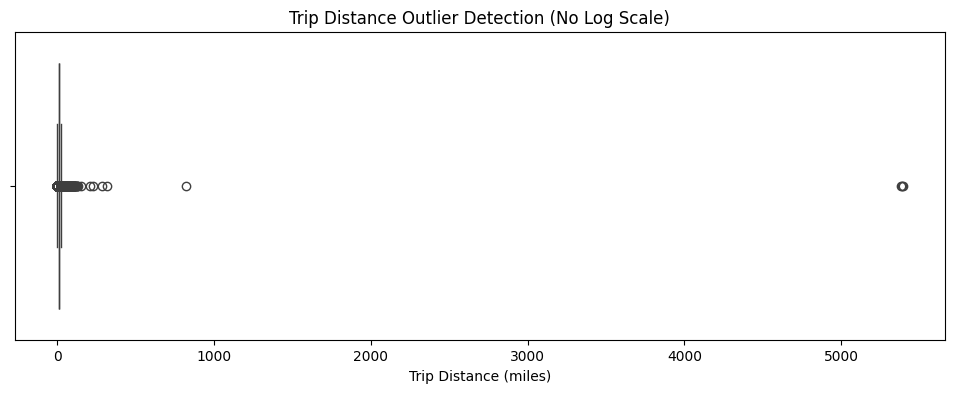

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,4))
sns.boxplot(x=df['trip_distance'])
plt.title("Trip Distance Outlier Detection (No Log Scale)")
plt.xlabel("Trip Distance (miles)")
plt.show()

In [ ]:
df[df.trip_distance > 150]

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,tip_amount,tolls_amount
9657202,2024-04-30 17:19:53,2024-04-30 18:11:00,1.0,317.63,2.0,132,186,70.0,5.0,17.54,6.94
19043146,2024-07-19 22:19:48,2024-07-19 22:55:13,1.0,152.08,1.0,138,100,51.3,6.0,13.65,6.94
22040324,2024-08-18 21:51:10,2024-08-18 22:08:34,1.0,5384.61,1.0,138,78,19.8,6.0,5.00,6.94
24313976,2024-09-10 09:35:39,2024-09-10 10:47:36,2.0,818.59,1.0,138,161,66.0,5.0,16.39,6.94
25967617,2024-09-25 15:05:39,2024-09-25 16:00:12,1.0,5379.99,1.0,138,143,48.5,5.0,12.89,6.94
27070061,2024-12-01 08:34:11,2024-12-01 08:54:36,3.0,225.99,1.0,138,237,33.1,5.0,10.16,6.94
27441740,2024-12-04 16:46:50,2024-12-04 17:21:05,1.0,282.89,1.0,138,170,30.3,7.5,9.75,6.94
27504528,2024-12-05 06:33:59,2024-12-05 06:55:59,1.0,209.30,1.0,238,138,38.0,5.0,10.79,6.94
29287579,2024-12-19 09:07:40,2024-12-19 09:53:01,2.0,5390.74,1.0,265,138,53.4,5.0,14.87,11.94


In [ ]:
df = df[df.trip_distance < 150]

In [ ]:
df.describe().round(2)

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,tip_amount,tolls_amount
count,1220955,1220955,1220955.00,1220955.00,1220955.00,1220955.00,1220955.00,1220955.00,1220955.00,1220955.00,1220955.00
mean,2024-06-24 17:18:08.078848,2024-06-24 17:55:38.620286,1.37,11.80,1.28,144.80,158.46,51.41,5.44,11.82,7.27
min,2002-12-31 16:46:07,2002-12-31 17:24:07,1.00,0.00,1.00,1.00,1.00,0.01,0.01,0.00,0.01
25%,2024-04-11 21:44:25,2024-04-11 22:09:34.500000,1.00,8.91,1.00,132.00,132.00,38.70,5.00,9.59,6.94
50%,2024-06-13 16:29:11,2024-06-13 17:16:53,1.00,10.22,1.00,138.00,145.00,46.40,5.00,11.90,6.94
75%,2024-08-27 22:52:46,2024-08-27 23:20:54.500000,1.00,14.12,1.00,142.00,230.00,65.00,6.00,15.00,6.94
max,2026-06-26 23:26:55,2026-06-26 23:47:51,7.00,129.90,99.00,265.00,265.00,740.10,14.25,250.00,186.94
std,NaN,NaN,0.80,4.99,0.95,43.97,64.83,20.63,2.27,5.82,2.42


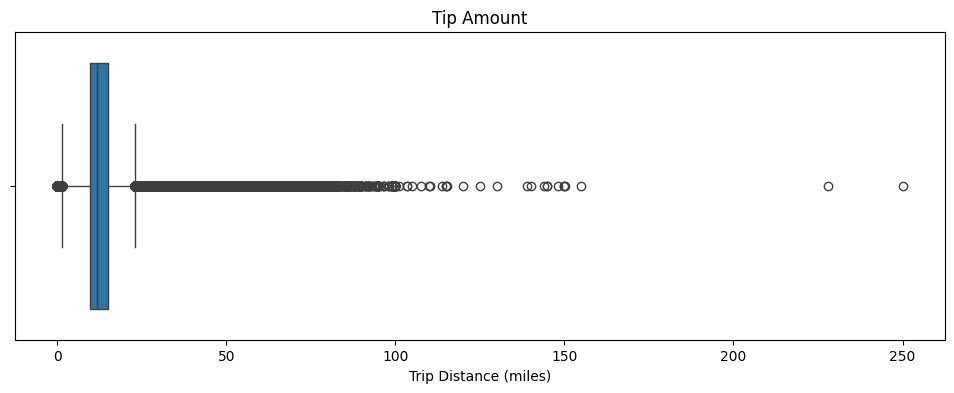

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,4))
sns.boxplot(x=df['tip_amount'])
plt.title("Tip Amount")
plt.xlabel("Trip Distance (miles)")
plt.show()

In [ ]:
df[df.tip_amount>100]

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,tip_amount,tolls_amount
126490,2024-02-02 10:45:56,2024-02-02 11:57:06,3.0,18.20,2.0,132,164,70.0,4.25,103.36,6.94
1179477,2024-02-13 01:56:54,2024-02-13 03:10:42,1.0,52.60,4.0,138,265,340.4,6.00,110.32,20.32
1723277,2024-02-18 18:25:03,2024-02-18 21:28:37,2.0,108.60,4.0,230,125,740.1,2.50,150.05,6.36
2560443,2024-02-27 17:40:31,2024-02-27 18:46:35,1.0,44.50,1.0,132,265,159.1,4.25,150.00,10.42
3617096,2024-03-06 23:20:16,2024-03-06 23:58:48,1.0,12.76,4.0,230,265,87.7,1.00,150.00,13.38
4125718,2024-03-11 22:43:44,2024-03-11 22:44:18,1.0,0.00,1.0,265,265,3.0,1.00,148.00,6.94
7474326,2024-04-09 16:08:15,2024-04-09 18:40:55,1.0,91.70,4.0,132,265,598.0,2.50,154.85,17.38
8404351,2024-04-18 13:06:55,2024-04-18 13:54:42,1.0,8.96,1.0,138,230,52.0,5.00,113.94,6.94
10531817,2024-05-04 17:49:38,2024-05-04 18:35:09,1.0,11.45,1.0,138,230,54.1,5.00,110.00,6.94
12522724,2024-05-22 18:50:20,2024-05-22 19:57:39,1.0,30.50,1.0,68,265,119.9,5.00,145.00,19.38


In [ ]:
df.describe().round(2)

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,tip_amount,tolls_amount
count,1220955,1220955,1220955.00,1220955.00,1220955.00,1220955.00,1220955.00,1220955.00,1220955.00,1220955.00,1220955.00
mean,2024-06-24 17:18:08.078848,2024-06-24 17:55:38.620286,1.37,11.80,1.28,144.80,158.46,51.41,5.44,11.82,7.27
min,2002-12-31 16:46:07,2002-12-31 17:24:07,1.00,0.00,1.00,1.00,1.00,0.01,0.01,0.00,0.01
25%,2024-04-11 21:44:25,2024-04-11 22:09:34.500000,1.00,8.91,1.00,132.00,132.00,38.70,5.00,9.59,6.94
50%,2024-06-13 16:29:11,2024-06-13 17:16:53,1.00,10.22,1.00,138.00,145.00,46.40,5.00,11.90,6.94
75%,2024-08-27 22:52:46,2024-08-27 23:20:54.500000,1.00,14.12,1.00,142.00,230.00,65.00,6.00,15.00,6.94
max,2026-06-26 23:26:55,2026-06-26 23:47:51,7.00,129.90,99.00,265.00,265.00,740.10,14.25,250.00,186.94
std,NaN,NaN,0.80,4.99,0.95,43.97,64.83,20.63,2.27,5.82,2.42


In [ ]:
df.shape

(1220955, 11)

# Feature Engineering

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1220955 entries, 44 to 30398614
Data columns (total 11 columns):
 #   Column                 Non-Null Count    Dtype         
---  ------                 --------------    -----         
 0   tpep_pickup_datetime   1220955 non-null  datetime64[us]
 1   tpep_dropoff_datetime  1220955 non-null  datetime64[us]
 2   passenger_count        1220955 non-null  float64       
 3   trip_distance          1220955 non-null  float64       
 4   RatecodeID             1220955 non-null  float64       
 5   PULocationID           1220955 non-null  int32         
 6   DOLocationID           1220955 non-null  int32         
 7   fare_amount            1220955 non-null  float64       
 8   extra                  1220955 non-null  float64       
 9   tip_amount             1220955 non-null  float64       
 10  tolls_amount           1220955 non-null  float64       
dtypes: datetime64[us](2), float64(7), int32(2)
memory usage: 102.5 MB


In [ ]:
df['pickup_month'] = df['tpep_pickup_datetime'].dt.month
df['pickup_day'] = df['tpep_pickup_datetime'].dt.day
df['pickup_hour'] = df['tpep_pickup_datetime'].dt.hour
df['pickup_weekday'] = df['tpep_pickup_datetime'].dt.weekday
df['is_weekend'] = df['pickup_weekday'].isin([5, 6]).astype(int)
df['is_rush_hour'] = df['pickup_hour'].isin([7,8,9,16,17,18]).astype(int)

In [ ]:
 def time_of_day(h):
    if 5 <= h < 12:
        return 'morning'
    elif 12 <= h < 17:
        return 'afternoon'
    elif 17 <= h < 21:
        return 'evening'
    else:
        return 'night'

df['time_of_day'] = df['pickup_hour'].apply(time_of_day)

In [ ]:
df.head()

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,tip_amount,tolls_amount,pickup_month,pickup_day,pickup_hour,pickup_weekday,is_weekend,is_rush_hour,time_of_day
44,2024-02-01 00:45:54,2024-02-01 01:34:40,1.0,20.30,2.0,132,140,70.0,4.25,10.00,6.94,2,1,0,3,0,0,night
50,2024-02-01 00:11:49,2024-02-01 00:46:30,1.0,19.00,2.0,132,75,70.0,1.75,20.00,6.94,2,1,0,3,0,0,night
119,2024-02-01 00:28:01,2024-02-01 01:16:16,3.0,31.83,3.0,138,1,136.4,6.00,0.00,20.32,2,1,0,3,0,0,night
130,2024-02-01 00:03:41,2024-02-01 00:22:34,1.0,9.92,1.0,138,162,38.7,6.00,2.87,6.94,2,1,0,3,0,0,night
138,2024-02-01 00:00:26,2024-02-01 00:14:21,1.0,7.99,1.0,138,262,31.7,6.00,10.08,6.94,2,1,0,3,0,0,night


In [ ]:
df["same_day"] = df["tpep_pickup_datetime"].dt.date == df["tpep_dropoff_datetime"].dt.date
df["same_day"].value_counts()

,count
same_day,
True,1197631
False,23324


In [ ]:
df["trip_duration_min"] = (
    df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]
).dt.total_seconds() / 60
df["trip_duration_min"].describe().round(2)

,trip_duration_min
count,1220955.00
mean,37.51
std,34.35
min,0.00
25%,24.02
50%,33.18
75%,46.00
max,1439.95


In [ ]:
df[df["trip_duration_min"] < 0]

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,tip_amount,tolls_amount,pickup_month,pickup_day,pickup_hour,pickup_weekday,is_weekend,is_rush_hour,time_of_day,same_day,trip_duration_min


In [ ]:
df = df[df["trip_duration_min"] > 0]
df["trip_duration_min"].describe().round(2)

,trip_duration_min
count,1220919.00
mean,37.51
std,34.35
min,0.02
25%,24.02
50%,33.18
75%,46.00
max,1439.95


In [ ]:
df["speed_mph"] = df["trip_distance"] / (df["trip_duration_min"] / 60)

In [ ]:
df.head()

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,tip_amount,...,pickup_month,pickup_day,pickup_hour,pickup_weekday,is_weekend,is_rush_hour,time_of_day,same_day,trip_duration_min,speed_mph
44,2024-02-01 00:45:54,2024-02-01 01:34:40,1.0,20.30,2.0,132,140,70.0,4.25,10.00,...,2,1,0,3,0,0,night,True,48.766667,24.976077
50,2024-02-01 00:11:49,2024-02-01 00:46:30,1.0,19.00,2.0,132,75,70.0,1.75,20.00,...,2,1,0,3,0,0,night,True,34.683333,32.868813
119,2024-02-01 00:28:01,2024-02-01 01:16:16,3.0,31.83,3.0,138,1,136.4,6.00,0.00,...,2,1,0,3,0,0,night,True,48.250000,39.581347
130,2024-02-01 00:03:41,2024-02-01 00:22:34,1.0,9.92,1.0,138,162,38.7,6.00,2.87,...,2,1,0,3,0,0,night,True,18.883333,31.519859
138,2024-02-01 00:00:26,2024-02-01 00:14:21,1.0,7.99,1.0,138,262,31.7,6.00,10.08,...,2,1,0,3,0,0,night,True,13.916667,34.447904


In [ ]:
df.columns

Index(['tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count',
       'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID',
       'fare_amount', 'extra', 'tip_amount', 'tolls_amount', 'pickup_month',
       'pickup_day', 'pickup_hour', 'pickup_weekday', 'is_weekend',
       'is_rush_hour', 'time_of_day', 'same_day', 'trip_duration_min',
       'speed_mph'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1220919 entries, 44 to 30398614
Data columns (total 21 columns):
 #   Column                 Non-Null Count    Dtype         
---  ------                 --------------    -----         
 0   tpep_pickup_datetime   1220919 non-null  datetime64[us]
 1   tpep_dropoff_datetime  1220919 non-null  datetime64[us]
 2   passenger_count        1220919 non-null  float64       
 3   trip_distance          1220919 non-null  float64       
 4   RatecodeID             1220919 non-null  float64       
 5   PULocationID           1220919 non-null  int32         
 6   DOLocationID           1220919 non-null  int32         
 7   fare_amount            1220919 non-null  float64       
 8   extra                  1220919 non-null  float64       
 9   tip_amount             1220919 non-null  float64       
 10  tolls_amount           1220919 non-null  float64       
 11  pickup_month           1220919 non-null  int32         
 12  pickup_day             1220919 

#Sample Data from main df

In [ ]:
# Do this so that its faster to process
df_10000 = df.sample(10000, random_state=67)
df_10000

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,tip_amount,...,pickup_month,pickup_day,pickup_hour,pickup_weekday,is_weekend,is_rush_hour,time_of_day,same_day,trip_duration_min,speed_mph
9653340,2024-04-30 17:23:07,2024-04-30 17:55:46,1.0,10.00,1.0,138,161,43.6,11.75,12.75,...,4,30,17,1,0,1,evening,True,32.650000,18.376723
8006483,2024-04-14 14:10:58,2024-04-14 14:39:04,1.0,8.70,1.0,138,170,39.4,9.25,8.00,...,4,14,14,6,1,0,afternoon,True,28.100000,18.576512
18588921,2024-07-15 16:07:25,2024-07-15 17:08:37,2.0,19.50,2.0,236,132,70.0,7.50,18.55,...,7,15,16,0,0,1,afternoon,True,61.200000,19.117647
11438109,2024-05-12 20:52:56,2024-05-12 21:17:41,1.0,9.37,1.0,138,244,40.1,6.00,11.26,...,5,12,20,6,1,0,evening,True,24.750000,22.715152
26225485,2024-09-27 19:50:49,2024-09-27 20:23:29,1.0,10.00,1.0,138,234,44.3,11.75,12.85,...,9,27,19,4,0,0,evening,True,32.666667,18.367347
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10618547,2024-05-05 13:56:15,2024-05-05 14:37:21,1.0,9.54,1.0,138,161,46.4,5.00,12.47,...,5,5,13,6,1,0,afternoon,True,41.100000,13.927007
15066579,2024-06-12 16:42:30,2024-06-12 17:34:22,1.0,9.70,1.0,138,48,53.4,11.75,14.70,...,6,12,16,2,0,1,afternoon,True,51.866667,11.221080
24610580,2024-09-12 21:51:22,2024-09-12 22:10:20,1.0,4.23,1.0,88,181,22.6,1.00,10.36,...,9,12,21,3,0,0,night,True,18.966667,13.381371
656421,2024-02-07 19:47:15,2024-02-07 20:25:29,1.0,14.72,1.0,138,125,60.4,7.50,15.77,...,2,7,19,2,0,0,evening,True,38.233333,23.100262


In [ ]:
url = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"
taxi_zone_df = pd.read_csv(url)
taxi_zone_df

,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone
...,...,...,...,...
260,261,Manhattan,World Trade Center,Yellow Zone
261,262,Manhattan,Yorkville East,Yellow Zone
262,263,Manhattan,Yorkville West,Yellow Zone
263,264,Unknown,NaN,NaN


In [ ]:
taxi_zone_df[taxi_zone_df.Borough=="Bronx"]

,LocationID,Borough,Zone,service_zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
17,18,Bronx,Bedford Park,Boro Zone
19,20,Bronx,Belmont,Boro Zone
30,31,Bronx,Bronx Park,Boro Zone
31,32,Bronx,Bronxdale,Boro Zone
45,46,Bronx,City Island,Boro Zone
46,47,Bronx,Claremont/Bathgate,Boro Zone
50,51,Bronx,Co-Op City,Boro Zone
57,58,Bronx,Country Club,Boro Zone
58,59,Bronx,Crotona Park,Boro Zone


In [ ]:
# Merge Pickup Location Info
df_10000 = df_10000.merge(
    taxi_zone_df,
    how="left",
    left_on="PULocationID",
    right_on="LocationID"
)

df_10000 = df_10000.rename(columns={
    "Borough": "pickup_borough",
    "Zone": "pickup_zone",
    "service_zone": "pickup_service_zone"
})

df_10000 = df_10000.drop(columns=["LocationID"])   # remove duplicate key column


# Merge Drop-Off Location Info
df_10000 = df_10000.merge(
    taxi_zone_df,
    how="left",
    left_on="DOLocationID",
    right_on="LocationID"
)

df_10000 = df_10000.rename(columns={
    "Borough": "dropoff_borough",
    "Zone": "dropoff_zone",
    "service_zone": "dropoff_service_zone"
})

df_10000 = df_10000.drop(columns=["LocationID"])

In [ ]:
df_10000

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,tip_amount,...,time_of_day,same_day,trip_duration_min,speed_mph,pickup_borough,pickup_zone,pickup_service_zone,dropoff_borough,dropoff_zone,dropoff_service_zone
0,2024-04-30 17:23:07,2024-04-30 17:55:46,1.0,10.00,1.0,138,161,43.6,11.75,12.75,...,evening,True,32.650000,18.376723,Queens,LaGuardia Airport,Airports,Manhattan,Midtown Center,Yellow Zone
1,2024-04-14 14:10:58,2024-04-14 14:39:04,1.0,8.70,1.0,138,170,39.4,9.25,8.00,...,afternoon,True,28.100000,18.576512,Queens,LaGuardia Airport,Airports,Manhattan,Murray Hill,Yellow Zone
2,2024-07-15 16:07:25,2024-07-15 17:08:37,2.0,19.50,2.0,236,132,70.0,7.50,18.55,...,afternoon,True,61.200000,19.117647,Manhattan,Upper East Side North,Yellow Zone,Queens,JFK Airport,Airports
3,2024-05-12 20:52:56,2024-05-12 21:17:41,1.0,9.37,1.0,138,244,40.1,6.00,11.26,...,evening,True,24.750000,22.715152,Queens,LaGuardia Airport,Airports,Manhattan,Washington Heights South,Boro Zone
4,2024-09-27 19:50:49,2024-09-27 20:23:29,1.0,10.00,1.0,138,234,44.3,11.75,12.85,...,evening,True,32.666667,18.367347,Queens,LaGuardia Airport,Airports,Manhattan,Union Sq,Yellow Zone
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,2024-05-05 13:56:15,2024-05-05 14:37:21,1.0,9.54,1.0,138,161,46.4,5.00,12.47,...,afternoon,True,41.100000,13.927007,Queens,LaGuardia Airport,Airports,Manhattan,Midtown Center,Yellow Zone
9996,2024-06-12 16:42:30,2024-06-12 17:34:22,1.0,9.70,1.0,138,48,53.4,11.75,14.70,...,afternoon,True,51.866667,11.221080,Queens,LaGuardia Airport,Airports,Manhattan,Clinton East,Yellow Zone
9997,2024-09-12 21:51:22,2024-09-12 22:10:20,1.0,4.23,1.0,88,181,22.6,1.00,10.36,...,night,True,18.966667,13.381371,Manhattan,Financial District South,Yellow Zone,Brooklyn,Park Slope,Boro Zone
9998,2024-02-07 19:47:15,2024-02-07 20:25:29,1.0,14.72,1.0,138,125,60.4,7.50,15.77,...,evening,True,38.233333,23.100262,Queens,LaGuardia Airport,Airports,Manhattan,Hudson Sq,Yellow Zone


# Joining Lat and Long with dataset


In [ ]:
import geopandas as gpd

#importing file using google drive

# Jack's file path
shapefile_path = "/content/drive/MyDrive/Data Analytics Project/Project Data/Taxi Zone Shape Files/taxi_zones.shp"

# Pat file path
# shapefile_path = "/content/drive/MyDrive/Data Analytics Project/Project Data/Taxi Zone Shape Files/taxi_zones.shp"

zones_gdf = gpd.read_file(shapefile_path)
zones_gdf.head()

,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((933100.918 192536.086, 933091.011 19..."
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((1033269.244 172126.008, 103343..."
2,3,0.084341,0.000314,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((1026308.77 256767.698, 1026495.593 2..."
3,4,0.043567,0.000112,Alphabet City,4,Manhattan,"POLYGON ((992073.467 203714.076, 992068.667 20..."
4,5,0.092146,0.000498,Arden Heights,5,Staten Island,"POLYGON ((935843.31 144283.336, 936046.565 144..."


In [ ]:
# Reproject to WGS84 (lat and lon)
zones_gdf = zones_gdf.to_crs(epsg=4326)

# Compute centroids and extract lat and lon
zones_gdf["centroid"] = zones_gdf.geometry.centroid
zones_gdf["lat"] = zones_gdf["centroid"].y
zones_gdf["lon"] = zones_gdf["centroid"].x

zones_coords = zones_gdf[["LocationID", "zone", "borough", "lat", "lon"]]
zones_coords

/tmp/ipython-input-230223445.py:5: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  zones_gdf["centroid"] = zones_gdf.geometry.centroid


,LocationID,zone,borough,lat,lon
0,1,Newark Airport,EWR,40.691831,-74.174000
1,2,Jamaica Bay,Queens,40.616745,-73.831299
2,3,Allerton/Pelham Gardens,Bronx,40.864474,-73.847422
3,4,Alphabet City,Manhattan,40.723752,-73.976968
4,5,Arden Heights,Staten Island,40.552659,-74.188484
...,...,...,...,...,...
258,259,Woodlawn/Wakefield,Bronx,40.897932,-73.852215
259,260,Woodside,Queens,40.744235,-73.906306
260,261,World Trade Center,Manhattan,40.709139,-74.013023
261,262,Yorkville East,Manhattan,40.775932,-73.946510


In [ ]:
df_10000 = df_10000.merge(
    zones_coords[["LocationID", "lat", "lon"]].rename(
        columns={
            "LocationID": "PULocationID",
            "lat": "pickup_lat",
            "lon": "pickup_lon"
        }
    ),
    how="left",
    on="PULocationID"
)

df_10000 = df_10000.merge(
    zones_coords[["LocationID", "lat", "lon"]].rename(
        columns={
            "LocationID": "DOLocationID",
            "lat": "dropoff_lat",
            "lon": "dropoff_lon"
        }
    ),
    how="left",
    on="DOLocationID"
)

In [ ]:
df_10000

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,tip_amount,...,pickup_borough,pickup_zone,pickup_service_zone,dropoff_borough,dropoff_zone,dropoff_service_zone,pickup_lat,pickup_lon,dropoff_lat,dropoff_lon
0,2024-04-30 17:23:07,2024-04-30 17:55:46,1.0,10.00,1.0,138,161,43.6,11.75,12.75,...,Queens,LaGuardia Airport,Airports,Manhattan,Midtown Center,Yellow Zone,40.774376,-73.873629,40.758028,-73.977698
1,2024-04-14 14:10:58,2024-04-14 14:39:04,1.0,8.70,1.0,138,170,39.4,9.25,8.00,...,Queens,LaGuardia Airport,Airports,Manhattan,Murray Hill,Yellow Zone,40.774376,-73.873629,40.747746,-73.978492
2,2024-07-15 16:07:25,2024-07-15 17:08:37,2.0,19.50,2.0,236,132,70.0,7.50,18.55,...,Manhattan,Upper East Side North,Yellow Zone,Queens,JFK Airport,Airports,40.780436,-73.957012,40.646985,-73.786533
3,2024-05-12 20:52:56,2024-05-12 21:17:41,1.0,9.37,1.0,138,244,40.1,6.00,11.26,...,Queens,LaGuardia Airport,Airports,Manhattan,Washington Heights South,Boro Zone,40.774376,-73.873629,40.841709,-73.941399
4,2024-09-27 19:50:49,2024-09-27 20:23:29,1.0,10.00,1.0,138,234,44.3,11.75,12.85,...,Queens,LaGuardia Airport,Airports,Manhattan,Union Sq,Yellow Zone,40.774376,-73.873629,40.740337,-73.990458
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9999,2024-05-05 13:56:15,2024-05-05 14:37:21,1.0,9.54,1.0,138,161,46.4,5.00,12.47,...,Queens,LaGuardia Airport,Airports,Manhattan,Midtown Center,Yellow Zone,40.774376,-73.873629,40.758028,-73.977698
10000,2024-06-12 16:42:30,2024-06-12 17:34:22,1.0,9.70,1.0,138,48,53.4,11.75,14.70,...,Queens,LaGuardia Airport,Airports,Manhattan,Clinton East,Yellow Zone,40.774376,-73.873629,40.762253,-73.989845
10001,2024-09-12 21:51:22,2024-09-12 22:10:20,1.0,4.23,1.0,88,181,22.6,1.00,10.36,...,Manhattan,Financial District South,Yellow Zone,Brooklyn,Park Slope,Boro Zone,40.703358,-74.011515,40.670374,-73.981414
10002,2024-02-07 19:47:15,2024-02-07 20:25:29,1.0,14.72,1.0,138,125,60.4,7.50,15.77,...,Queens,LaGuardia Airport,Airports,Manhattan,Hudson Sq,Yellow Zone,40.774376,-73.873629,40.726290,-74.007486


# Adding Weather using Lat and Long

In [ ]:
df_10000

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,tip_amount,...,pickup_borough,pickup_zone,pickup_service_zone,dropoff_borough,dropoff_zone,dropoff_service_zone,pickup_lat,pickup_lon,dropoff_lat,dropoff_lon
0,2024-04-30 17:23:07,2024-04-30 17:55:46,1.0,10.00,1.0,138,161,43.6,11.75,12.75,...,Queens,LaGuardia Airport,Airports,Manhattan,Midtown Center,Yellow Zone,40.774376,-73.873629,40.758028,-73.977698
1,2024-04-14 14:10:58,2024-04-14 14:39:04,1.0,8.70,1.0,138,170,39.4,9.25,8.00,...,Queens,LaGuardia Airport,Airports,Manhattan,Murray Hill,Yellow Zone,40.774376,-73.873629,40.747746,-73.978492
2,2024-07-15 16:07:25,2024-07-15 17:08:37,2.0,19.50,2.0,236,132,70.0,7.50,18.55,...,Manhattan,Upper East Side North,Yellow Zone,Queens,JFK Airport,Airports,40.780436,-73.957012,40.646985,-73.786533
3,2024-05-12 20:52:56,2024-05-12 21:17:41,1.0,9.37,1.0,138,244,40.1,6.00,11.26,...,Queens,LaGuardia Airport,Airports,Manhattan,Washington Heights South,Boro Zone,40.774376,-73.873629,40.841709,-73.941399
4,2024-09-27 19:50:49,2024-09-27 20:23:29,1.0,10.00,1.0,138,234,44.3,11.75,12.85,...,Queens,LaGuardia Airport,Airports,Manhattan,Union Sq,Yellow Zone,40.774376,-73.873629,40.740337,-73.990458
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9999,2024-05-05 13:56:15,2024-05-05 14:37:21,1.0,9.54,1.0,138,161,46.4,5.00,12.47,...,Queens,LaGuardia Airport,Airports,Manhattan,Midtown Center,Yellow Zone,40.774376,-73.873629,40.758028,-73.977698
10000,2024-06-12 16:42:30,2024-06-12 17:34:22,1.0,9.70,1.0,138,48,53.4,11.75,14.70,...,Queens,LaGuardia Airport,Airports,Manhattan,Clinton East,Yellow Zone,40.774376,-73.873629,40.762253,-73.989845
10001,2024-09-12 21:51:22,2024-09-12 22:10:20,1.0,4.23,1.0,88,181,22.6,1.00,10.36,...,Manhattan,Financial District South,Yellow Zone,Brooklyn,Park Slope,Boro Zone,40.703358,-74.011515,40.670374,-73.981414
10002,2024-02-07 19:47:15,2024-02-07 20:25:29,1.0,14.72,1.0,138,125,60.4,7.50,15.77,...,Queens,LaGuardia Airport,Airports,Manhattan,Hudson Sq,Yellow Zone,40.774376,-73.873629,40.726290,-74.007486


In [ ]:

df_10000["pickup_hour"] = pd.to_datetime(df_10000["pickup_hour"])



In [ ]:
coords_times = (
    df_10000[["pickup_hour", "pickup_lat", "pickup_lon"]]
    .drop_duplicates()
    .reset_index(drop=True)
)
coords_times.head()

,pickup_hour,pickup_lat,pickup_lon
0,1970-01-01 00:00:00.000000017,40.774376,-73.873629
1,1970-01-01 00:00:00.000000014,40.774376,-73.873629
2,1970-01-01 00:00:00.000000016,40.780436,-73.957012
3,1970-01-01 00:00:00.000000020,40.774376,-73.873629
4,1970-01-01 00:00:00.000000019,40.774376,-73.873629


#Calling Weather API

Weather API
https://open-meteo.com/

Test Weather API
https://archive-api.open-meteo.com/v1/archive?latitude=40.7128&longitude=-74.0060&start_date=2024-01-01&end_date=2024-12-31&hourly=temperature_2m,precipitation,rain,snowfall,weathercode&timezone=America%2FNew_York


In [ ]:
from tqdm import tqdm
import requests

weather_records = []

for _, row in tqdm(coords_times.iterrows(), total=len(coords_times)):
    lat = row["pickup_lat"]
    lon = row["pickup_lon"]
    hour = row["pickup_hour"]

    url = (
        "https://archive-api.open-meteo.com/v1/archive?"
        f"latitude={lat}&longitude={lon}"
        f"&start_date={hour.date()}&end_date={hour.date()}"
        "&hourly=temperature_2m,precipitation,rain,snowfall,weathercode"
        "&timezone=America/New_York"
    )
    try:
      response = requests.get(url, timeout=10).json()
    except Exception:
      print(lat, lon, hour)
      continue
    if "hourly" in response:
        timestamps = pd.to_datetime(response["hourly"]["time"])
        idx = (timestamps == hour)

        if idx.any():
            i = list(idx).index(True)
            weather_records.append({
                "pickup_hour": hour,
                "pickup_lat": lat,
                "pickup_lon": lon,
                "temperature": response["hourly"]["temperature_2m"][i],
                "precipitation": response["hourly"]["precipitation"][i],
                "rain": response["hourly"]["rain"][i],
                "snowfall": response["hourly"]["snowfall"][i],
                "weathercode": response["hourly"]["weathercode"][i]
            })


 34%|███▎      | 327/969 [02:31<35:39,  3.33s/it]

NaT NaT 1970-01-01 00:00:00


 80%|████████  | 777/969 [05:54<10:39,  3.33s/it]

40.78396143031379 -73.97863194845084 1970-01-01 00:00:00.000000006


100%|██████████| 969/969 [07:16<00:00,  2.22it/s]


In [ ]:
weather_df = pd.DataFrame(weather_records)
weather_df.head()

,pickup_hour,pickup_lat,pickup_lon,temperature,precipitation,rain,snowfall,weathercode
0,1970-01-01,40.774376,-73.873629,-6.5,0.0,0.0,0.0,2
1,1970-01-01,40.740337,-73.990458,-6.5,0.0,0.0,0.0,2
2,1970-01-01,40.728340,-73.997380,-6.3,0.0,0.0,0.0,2
3,1970-01-01,40.646985,-73.786533,-6.5,0.0,0.0,0.0,2
4,1970-01-01,40.758028,-73.977698,-6.7,0.0,0.0,0.0,2


In [ ]:
# Merging weather data

df_10000 = df_10000.merge(
    weather_df,
    on=["pickup_hour", "pickup_lat", "pickup_lon"],
    how="left"
)
df_10000.head()

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,tip_amount,...,dropoff_service_zone,pickup_lat,pickup_lon,dropoff_lat,dropoff_lon,temperature,precipitation,rain,snowfall,weathercode
0,2024-04-30 17:23:07,2024-04-30 17:55:46,1.0,10.00,1.0,138,161,43.6,11.75,12.75,...,Yellow Zone,40.774376,-73.873629,40.758028,-73.977698,NaN,NaN,NaN,NaN,NaN
1,2024-04-14 14:10:58,2024-04-14 14:39:04,1.0,8.70,1.0,138,170,39.4,9.25,8.00,...,Yellow Zone,40.774376,-73.873629,40.747746,-73.978492,NaN,NaN,NaN,NaN,NaN
2,2024-07-15 16:07:25,2024-07-15 17:08:37,2.0,19.50,2.0,236,132,70.0,7.50,18.55,...,Airports,40.780436,-73.957012,40.646985,-73.786533,NaN,NaN,NaN,NaN,NaN
3,2024-05-12 20:52:56,2024-05-12 21:17:41,1.0,9.37,1.0,138,244,40.1,6.00,11.26,...,Boro Zone,40.774376,-73.873629,40.841709,-73.941399,NaN,NaN,NaN,NaN,NaN
4,2024-09-27 19:50:49,2024-09-27 20:23:29,1.0,10.00,1.0,138,234,44.3,11.75,12.85,...,Yellow Zone,40.774376,-73.873629,40.740337,-73.990458,NaN,NaN,NaN,NaN,NaN


In [ ]:
df_drop = df_10000.iloc[:, :38]
df_drop = df_drop.rename(columns=lambda col: col.replace("_x", ""))

In [ ]:
df_drop

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,tip_amount,...,dropoff_service_zone,pickup_lat,pickup_lon,dropoff_lat,dropoff_lon,temperature,precipitation,rain,snowfall,weathercode
0,2024-04-30 17:23:07,2024-04-30 17:55:46,1.0,10.00,1.0,138,161,43.6,11.75,12.75,...,Yellow Zone,40.774376,-73.873629,40.758028,-73.977698,NaN,NaN,NaN,NaN,NaN
1,2024-04-14 14:10:58,2024-04-14 14:39:04,1.0,8.70,1.0,138,170,39.4,9.25,8.00,...,Yellow Zone,40.774376,-73.873629,40.747746,-73.978492,NaN,NaN,NaN,NaN,NaN
2,2024-07-15 16:07:25,2024-07-15 17:08:37,2.0,19.50,2.0,236,132,70.0,7.50,18.55,...,Airports,40.780436,-73.957012,40.646985,-73.786533,NaN,NaN,NaN,NaN,NaN
3,2024-05-12 20:52:56,2024-05-12 21:17:41,1.0,9.37,1.0,138,244,40.1,6.00,11.26,...,Boro Zone,40.774376,-73.873629,40.841709,-73.941399,NaN,NaN,NaN,NaN,NaN
4,2024-09-27 19:50:49,2024-09-27 20:23:29,1.0,10.00,1.0,138,234,44.3,11.75,12.85,...,Yellow Zone,40.774376,-73.873629,40.740337,-73.990458,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9999,2024-05-05 13:56:15,2024-05-05 14:37:21,1.0,9.54,1.0,138,161,46.4,5.00,12.47,...,Yellow Zone,40.774376,-73.873629,40.758028,-73.977698,NaN,NaN,NaN,NaN,NaN
10000,2024-06-12 16:42:30,2024-06-12 17:34:22,1.0,9.70,1.0,138,48,53.4,11.75,14.70,...,Yellow Zone,40.774376,-73.873629,40.762253,-73.989845,NaN,NaN,NaN,NaN,NaN
10001,2024-09-12 21:51:22,2024-09-12 22:10:20,1.0,4.23,1.0,88,181,22.6,1.00,10.36,...,Boro Zone,40.703358,-74.011515,40.670374,-73.981414,NaN,NaN,NaN,NaN,NaN
10002,2024-02-07 19:47:15,2024-02-07 20:25:29,1.0,14.72,1.0,138,125,60.4,7.50,15.77,...,Yellow Zone,40.774376,-73.873629,40.726290,-74.007486,NaN,NaN,NaN,NaN,NaN


In [ ]:
df_drop.to_csv("data_with_weather.csv", index=False)

In [ ]:
from google.colab import files
files.download("data_with_weather.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#Changing weather code to name for dummy coding

In [ ]:
import pandas as pd
import glob
import os
from google.colab import drive
import matplotlib.pyplot as plt
import numpy as np

drive.mount('/content/drive')
# Jack's Path
path = "/content/drive/MyDrive/Data Analytics Project/Project Data/data_with_weather.csv"

df_weather = pd.read_csv(path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
weather_map = {
    0: "Clear sky",
    1: "Mainly clear",
    2: "Partly cloudy",
    3: "Overcast",
    45: "Fog",
    48: "Depositing rime fog",
    51: "Light drizzle",
    53: "Moderate drizzle",
    55: "Dense drizzle",
    56: "Light freezing drizzle",
    57: "Dense freezing drizzle",
    61: "Slight rain",
    63: "Moderate rain",
    65: "Heavy rain",
    66: "Light freezing rain",
    67: "Heavy freezing rain",
    71: "Slight snow fall",
    73: "Moderate snow fall",
    75: "Heavy snow fall",
    77: "Snow grains",
    80: "Slight rain showers",
    81: "Moderate rain showers",
    82: "Violent rain showers",
    85: "Slight snow showers",
    86: "Heavy snow showers",
    95: "Thunderstorm",
    96: "Thunderstorm with slight hail",
    97: "Thunderstorm with heavy hail"
}

In [ ]:
df_weather["weathercode_name"] = df_weather["weathercode"].map(weather_map)

In [ ]:
df_weather.head()

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,tip_amount,...,dropoff_lat,dropoff_lon,lat_round,lon_round,temperature,precipitation,rain,snowfall,weathercode,weathercode_name
0,2024-04-30 17:23:07,2024-04-30 17:55:46,1.0,10.00,1.0,138,161,43.6,11.75,12.75,...,40.758028,-73.977698,40.8,-73.9,17.9,0.0,0.0,0.0,3.0,Overcast
1,2024-04-14 14:10:58,2024-04-14 14:39:04,1.0,8.70,1.0,138,170,39.4,9.25,8.00,...,40.747746,-73.978492,40.8,-73.9,18.0,0.0,0.0,0.0,3.0,Overcast
2,2024-07-15 16:07:25,2024-07-15 17:08:37,2.0,19.50,2.0,236,132,70.0,7.50,18.55,...,40.646985,-73.786533,40.8,-74.0,34.3,0.0,0.0,0.0,0.0,Clear sky
3,2024-05-12 20:52:56,2024-05-12 21:17:41,1.0,9.37,1.0,138,244,40.1,6.00,11.26,...,40.841709,-73.941399,40.8,-73.9,9.5,0.0,0.0,0.0,1.0,Mainly clear
4,2024-09-27 19:50:49,2024-09-27 20:23:29,1.0,10.00,1.0,138,234,44.3,11.75,12.85,...,40.740337,-73.990458,40.8,-73.9,19.8,0.0,0.0,0.0,3.0,Overcast


#Join with Holiday data

In [ ]:
path = "/content/drive/MyDrive/Data Analytics Project/Project Data/ny_holidays_2024.csv"
hol = pd.read_csv(path)


hol["Date"] = pd.to_datetime(hol["Date"]).dt.date


df_weather["tpep_pickup_datetime"] = pd.to_datetime(df_weather["tpep_pickup_datetime"])
df_weather["pickup_date"] = df_weather["tpep_pickup_datetime"].dt.date

In [ ]:
df_weather = df_weather.merge(hol, left_on="pickup_date", right_on="Date", how="left")
df_weather["holiday"] = df_weather["Date"].notna().astype(int)

In [ ]:
df_weather = df_weather.drop(columns=["Date"])

In [ ]:
df_weather.loc[df_weather['holiday'] == 1, 'is_weekend'] = 1

In [ ]:
pd.set_option('display.max_columns', None)

df_weather.head()

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,tip_amount,tolls_amount,pickup_month,pickup_day,pickup_hour,pickup_weekday,is_weekend,is_rush_hour,time_of_day,same_day,trip_duration_min,speed_mph,pickup_borough,pickup_zone,pickup_service_zone,dropoff_borough,dropoff_zone,dropoff_service_zone,pickup_lat,pickup_lon,dropoff_lat,dropoff_lon,lat_round,lon_round,temperature,precipitation,rain,snowfall,weathercode,weathercode_name,pickup_date,holiday
0,2024-04-30 17:23:07,2024-04-30 17:55:46,1.0,10.00,1.0,138,161,43.6,11.75,12.75,6.94,4,30,2024-04-30 17:00:00,1,0,1,evening,True,32.650000,18.376723,Queens,LaGuardia Airport,Airports,Manhattan,Midtown Center,Yellow Zone,40.774376,-73.873629,40.758028,-73.977698,40.8,-73.9,17.9,0.0,0.0,0.0,3.0,Overcast,2024-04-30,0
1,2024-04-14 14:10:58,2024-04-14 14:39:04,1.0,8.70,1.0,138,170,39.4,9.25,8.00,6.94,4,14,2024-04-14 14:00:00,6,1,0,afternoon,True,28.100000,18.576512,Queens,LaGuardia Airport,Airports,Manhattan,Murray Hill,Yellow Zone,40.774376,-73.873629,40.747746,-73.978492,40.8,-73.9,18.0,0.0,0.0,0.0,3.0,Overcast,2024-04-14,0
2,2024-07-15 16:07:25,2024-07-15 17:08:37,2.0,19.50,2.0,236,132,70.0,7.50,18.55,13.88,7,15,2024-07-15 16:00:00,0,0,1,afternoon,True,61.200000,19.117647,Manhattan,Upper East Side North,Yellow Zone,Queens,JFK Airport,Airports,40.780436,-73.957012,40.646985,-73.786533,40.8,-74.0,34.3,0.0,0.0,0.0,0.0,Clear sky,2024-07-15,0
3,2024-05-12 20:52:56,2024-05-12 21:17:41,1.0,9.37,1.0,138,244,40.1,6.00,11.26,6.94,5,12,2024-05-12 20:00:00,6,1,0,evening,True,24.750000,22.715152,Queens,LaGuardia Airport,Airports,Manhattan,Washington Heights South,Boro Zone,40.774376,-73.873629,40.841709,-73.941399,40.8,-73.9,9.5,0.0,0.0,0.0,1.0,Mainly clear,2024-05-12,0
4,2024-09-27 19:50:49,2024-09-27 20:23:29,1.0,10.00,1.0,138,234,44.3,11.75,12.85,6.94,9,27,2024-09-27 19:00:00,4,0,0,evening,True,32.666667,18.367347,Queens,LaGuardia Airport,Airports,Manhattan,Union Sq,Yellow Zone,40.774376,-73.873629,40.740337,-73.990458,40.8,-73.9,19.8,0.0,0.0,0.0,3.0,Overcast,2024-09-27,0


In [ ]:
df_weather.to_csv("weather_holiday_taxi_data", index=False)

In [ ]:
from google.colab import files
files.download("weather_holiday_taxi_data")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
df_weather.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10004 entries, 0 to 10003
Data columns (total 41 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   tpep_pickup_datetime   10004 non-null  datetime64[ns]
 1   tpep_dropoff_datetime  10004 non-null  object        
 2   passenger_count        10004 non-null  float64       
 3   trip_distance          10004 non-null  float64       
 4   RatecodeID             10004 non-null  float64       
 5   PULocationID           10004 non-null  int64         
 6   DOLocationID           10004 non-null  int64         
 7   fare_amount            10004 non-null  float64       
 8   extra                  10004 non-null  float64       
 9   tip_amount             10004 non-null  float64       
 10  tolls_amount           10004 non-null  float64       
 11  pickup_month           10004 non-null  int64         
 12  pickup_day             10004 non-null  int64         
 13  p

# Exploratory Data Analysis and Visualisations

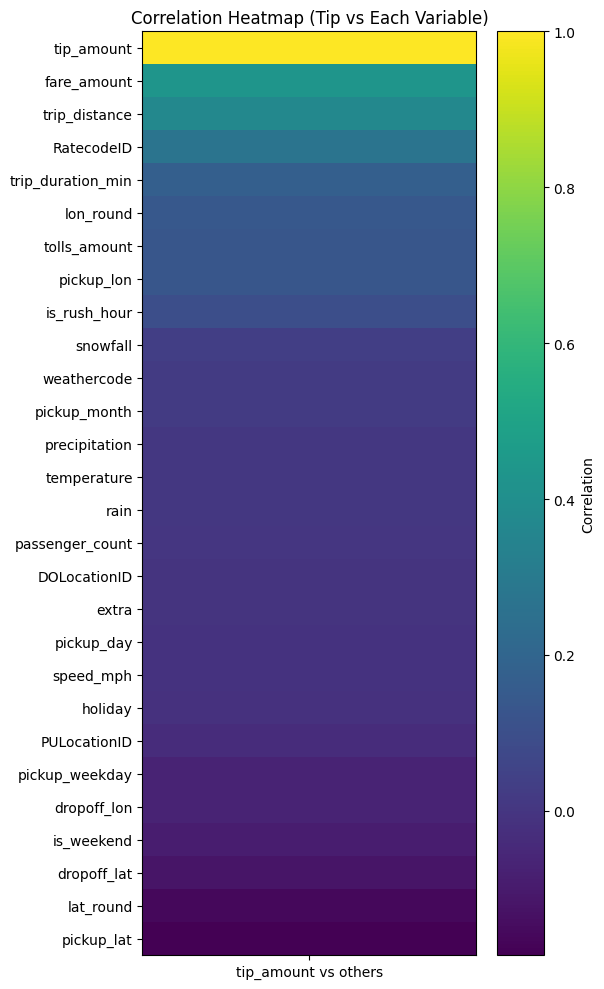

In [ ]:
numeric_cols = df_weather.select_dtypes(include='number')
corr = numeric_cols.corr()["tip_amount"].dropna().sort_values(ascending=False)
plt.figure(figsize=(6, 10))
plt.imshow(corr.values.reshape(-1, 1), cmap="viridis", aspect="auto")
plt.colorbar(label="Correlation")
plt.yticks(range(len(corr.index)), corr.index)
plt.xticks([0], ["tip_amount vs others"])
plt.title("Correlation Heatmap (Tip vs Each Variable)")
plt.tight_layout()
plt.show()


The correltion heatmap of tip verses each other independent variable suggests several promising predictors of the tip amount. Fare amount,trip distance and toll amount had correlations over 70%, but we also need to check for collineairty between predictors to ensure a valid model.

In [ ]:
def plot_correlation_analysis(df):
    """Comprehensive correlation analysis"""
    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    fig.suptitle('Feature Correlation Analysis', fontsize=16, fontweight='bold')

    # Select numerical features
    numerical_features = ['fare_amount', 'trip_distance', 'trip_duration_min',
                         'speed_mph', 'passenger_count', 'extra', 'tolls_amount',
                         'pickup_hour', 'pickup_day', 'pickup_month',
                         'is_weekend', 'is_rush_hour', 'tip_amount']

    # Calculate correlation matrix
    corr_matrix = df[numerical_features].corr()

    # 1. Full correlation heatmap
    sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
                center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8},
                ax=axes[0])
    axes[0].set_title('Feature Correlation Matrix', fontweight='bold', pad=15)

    # 2. Correlations with tip_amount
    tip_correlations = corr_matrix['tip_amount'].sort_values(ascending=False).drop('tip_amount')

    colors = ['green' if x > 0 else 'red' for x in tip_correlations.values]
    axes[1].barh(range(len(tip_correlations)), tip_correlations.values,
                color=colors, alpha=0.7, edgecolor='black')
    axes[1].set_yticks(range(len(tip_correlations)))
    axes[1].set_yticklabels(tip_correlations.index)
    axes[1].set_xlabel('Correlation Coefficient', fontsize=11)
    axes[1].set_title('Correlations with Tip Amount', fontweight='bold', pad=15)
    axes[1].axvline(x=0, color='black', linestyle='-', linewidth=0.8)
    axes[1].grid(axis='x', alpha=0.3)

    # Add values
    for i, v in enumerate(tip_correlations.values):
        axes[1].text(v + (0.01 if v > 0 else -0.01), i, f'{v:.3f}',
                    va='center', ha='left' if v > 0 else 'right', fontsize=9)

    plt.tight_layout()

In [ ]:
def plot_correlation_analysis(df):
    """Comprehensive correlation analysis"""
    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    fig.suptitle('Feature Correlation Analysis', fontsize=16, fontweight='bold')

    # Select numerical features that exist in the dataframe
    potential_features = ['fare_amount', 'trip_distance', 'trip_duration_min',
                         'speed_mph', 'passenger_count', 'extra', 'tolls_amount',
                         'pickup_hour', 'pickup_day', 'pickup_month',
                         'is_weekend', 'is_rush_hour', 'tip_amount']

    # Filter to only include columns that exist in df and are numeric
    numerical_features = [col for col in potential_features
                         if col in df.columns and df[col].dtype in ['int64', 'float64', 'int32', 'float32']]

    # Check if we have enough features
    if len(numerical_features) < 2:
        print(f"Error: Not enough numerical features found. Available numeric columns: {df.select_dtypes(include=['number']).columns.tolist()}")
        return

    if 'tip_amount' not in numerical_features:
        print("Warning: 'tip_amount' column not found or not numeric. Cannot show tip correlations.")
        return

    # Calculate correlation matrix
    corr_matrix = df[numerical_features].corr()

    # 1. Full correlation heatmap
    sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
                center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8},
                ax=axes[0])
    axes[0].set_title('Feature Correlation Matrix', fontweight='bold', pad=15)

    # 2. Correlations with tip_amount
    tip_correlations = corr_matrix['tip_amount'].sort_values(ascending=False).drop('tip_amount')

    colors = ['green' if x > 0 else 'red' for x in tip_correlations.values]
    axes[1].barh(range(len(tip_correlations)), tip_correlations.values,
                color=colors, alpha=0.7, edgecolor='black')
    axes[1].set_yticks(range(len(tip_correlations)))
    axes[1].set_yticklabels(tip_correlations.index)
    axes[1].set_xlabel('Correlation Coefficient', fontsize=11)
    axes[1].set_title('Correlations with Tip Amount', fontweight='bold', pad=15)
    axes[1].axvline(x=0, color='black', linestyle='-', linewidth=0.8)
    axes[1].grid(axis='x', alpha=0.3)

    # Add values
    for i, v in enumerate(tip_correlations.values):
        axes[1].text(v + (0.01 if v > 0 else -0.01), i, f'{v:.3f}',
                    va='center', ha='left' if v > 0 else 'right', fontsize=9)

    plt.tight_layout()

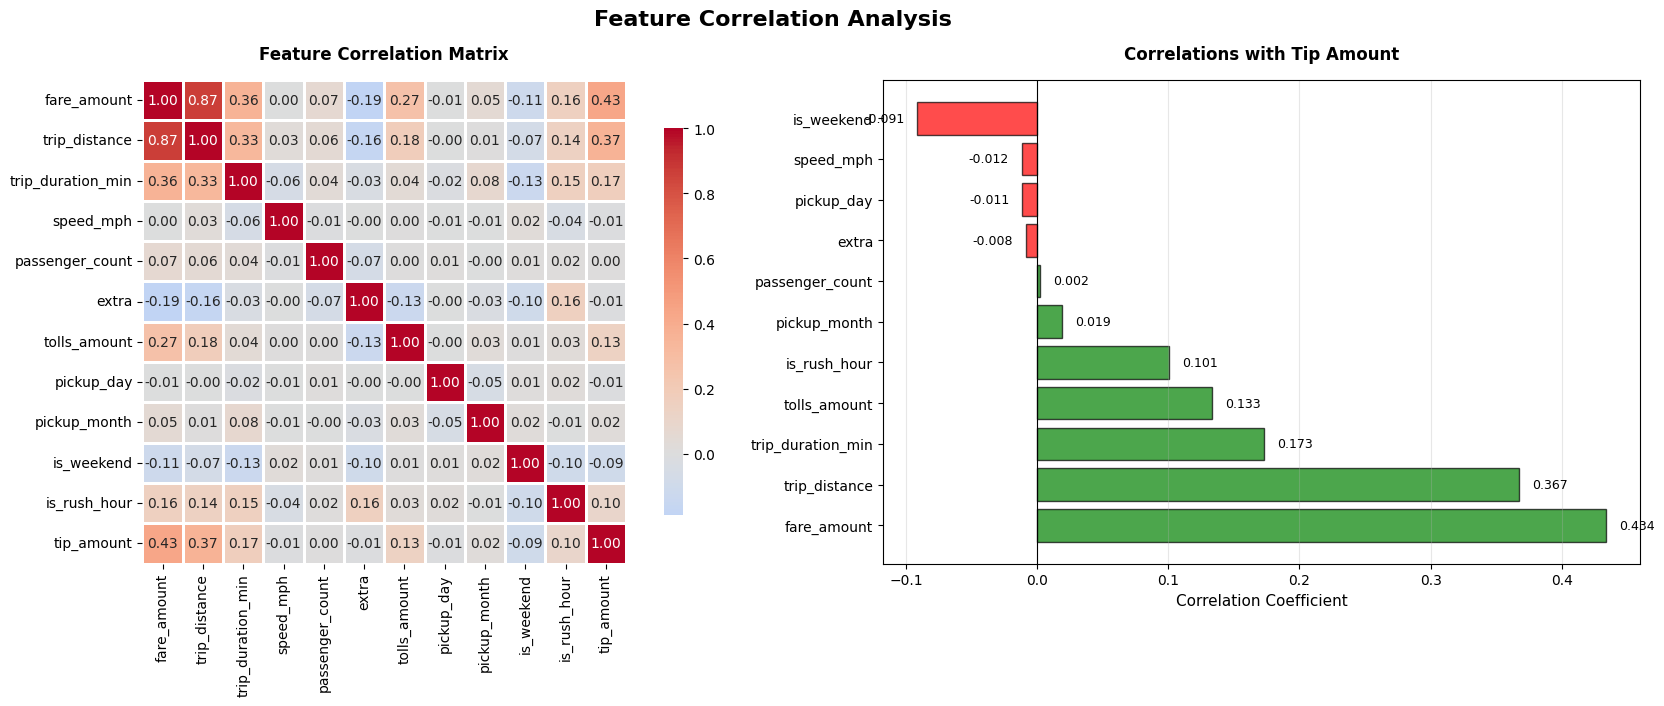

In [ ]:
plot_correlation_analysis(df_weather)

The correlation analysis reveals that NYC taxi tipping behavior is driven far more by trip value than by timing or rider characteristics. The strongest relationships across the dataset occur between fare amount, trip distance, and trip duration, and these same variables also show the highest positive correlation with tip amount, indicating that passengers tend to tip more on longer, higher-fare trips. In contrast, temporal and contextual features such as day of week, pickup hour, weekend indicators, or passenger count show very weak or negligible correlations, suggesting they play little role in predicting tips. A slight increase in tipping during rush hour hints at rider appreciation for difficult driving conditions, while weekends show marginally lower tips. Overall, the combined insights highlight a consistent story: tips in NYC are primarily influenced by the economic magnitude of the trip, not by when it occurs or who is riding.

### Chekcing Multicollinearity using VIF

In [ ]:
from statsmodels.tools.tools import add_constant
from statsmodels.stats.outliers_influence import variance_inflation_factor


# 1. Drop the dependent variable
df_cor = df_weather.drop(columns=["tip_amount"])

# 2. Keep only numeric columns
df_num = df_cor.select_dtypes(include=[np.number])

# 3. Replace inf/-inf with NaN
df_num = df_num.replace([np.inf, -np.inf], np.nan)

# 4. Drop rows with any NaN (for VIF calculation)
df_num = df_num.dropna()

# (Optional) reset index to keep things clean
# df_num = df_num.reset_index(drop=True)

# 5. Add constant
X_vif = add_constant(df_num)

# 6. Compute VIFs
vif_df = pd.DataFrame({
    "feature": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

# 7. Sort by VIF
vif_df_sorted = vif_df.sort_values(by="VIF", ascending=False)
vif_df_sorted


,feature,VIF
0,const,1.644929e+07
23,precipitation,3.749132e+05
24,rain,3.739004e+05
25,snowfall,1.323325e+03
21,lon_round,4.718503e+01
17,pickup_lon,4.370151e+01
16,pickup_lat,1.771658e+01
20,lat_round,1.493796e+01
6,fare_amount,5.516492e+00
2,trip_distance,5.515615e+00


The VIF test suggests some variables have moderate collinearity: fare_amount,trip_distance.Fare amount is mostly determined by trip distance + duration + tolls so some collinearity is unavoidable.

Distance,speed, and duration are inherently related so it is natural to have some correlation. Other variables have low VIF so no sings of multicollinearity. We should keep all the variables because even the ones with some collinearity are crucial predictors of the Taxi data.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled_cv = scaler.fit_transform(X_vif)

In [ ]:
from sklearn.linear_model import LassoCV

y_ = df_weather["tip_amount"]
y_matched = y_matched = y_.loc[df_num.index]
lasso = LassoCV(cv=5, random_state=0).fit(X_scaled_cv, y_matched)

coef = pd.Series(lasso.coef_, index=X_vif.columns)

# Sort from most important to least
coef_sorted = coef.sort_values(key=abs, ascending=False)
coef_sorted

,0
fare_amount,2.073614
extra,0.375223
trip_duration_min,0.212628
lat_round,0.186985
snowfall,0.143010
dropoff_lat,-0.138737
DOLocationID,0.131661
is_weekend,-0.095874
is_rush_hour,0.088731
passenger_count,-0.088484


The Lasso regression on.a small set of validation data from the training

### Analysing trip patterns across time dimension

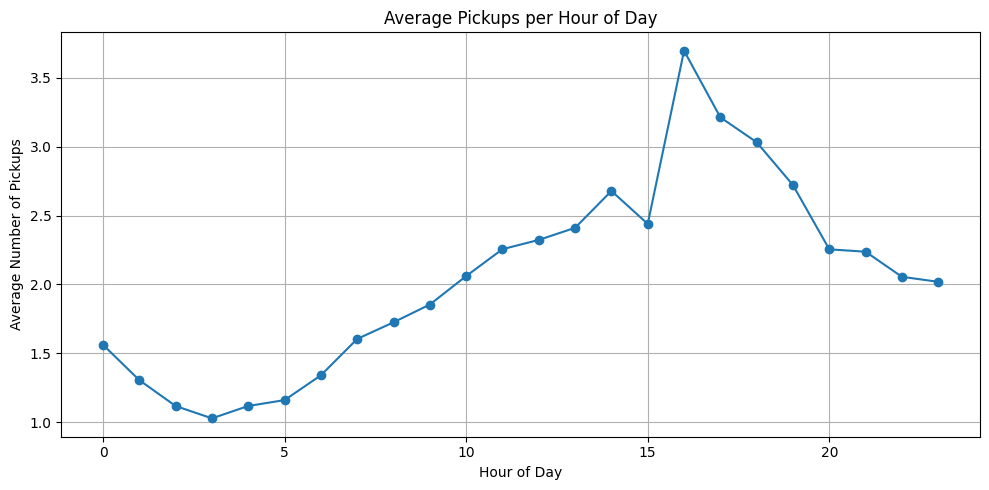

In [ ]:
df_weather["pickup_dt"] = pd.to_datetime(df_weather["tpep_pickup_datetime"], errors="coerce")

df_weather["pickup_hour"] = df_weather["pickup_dt"].dt.hour
df_weather["date"] = df_weather["pickup_dt"].dt.date


hourly_counts = df_weather.groupby(["date", "pickup_hour"]).size()

avg_by_hour = hourly_counts.groupby("pickup_hour").mean()


plt.figure(figsize=(10,5))
plt.plot(avg_by_hour.index, avg_by_hour.values, marker='o')
plt.xlabel("Hour of Day")
plt.ylabel("Average Number of Pickups")
plt.title("Average Pickups per Hour of Day")
plt.grid(True)
plt.tight_layout()
plt.show()

The plot shows that taxi pickups are lowest in the early morning hours, reaching their minimum between 2 AM and 5 AM. Activity gradually increases through the late morning and early afternoon. Pickups peak sharply around 4 PM–5 PM, reflecting the afternoon rush when both commuters and travelers have high demand of taxis. There is a small increase from 7 to 8pm likely relevant to dinner and social outings. Overall, the pattern reflects the daily demand of taxi trips in NYC, aligning with urban city work schedules and commuting behaviour.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

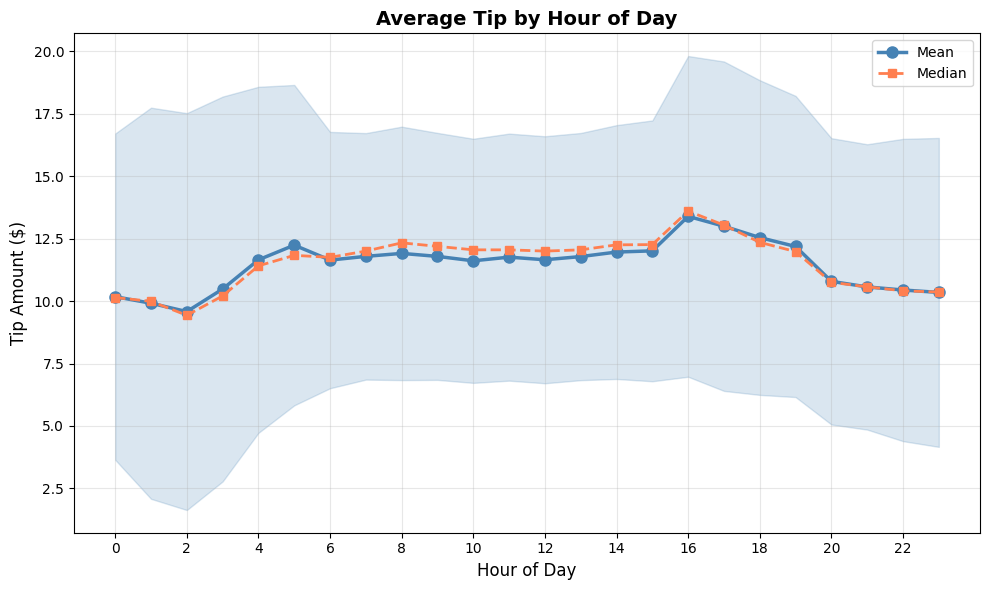

In [ ]:


# Group data
hourly_tips = df.groupby('pickup_hour')['tip_amount'].agg(['mean', 'median', 'std']).reset_index()

# Create figure
plt.figure(figsize=(10, 6))

# Plot mean tip
plt.plot(hourly_tips['pickup_hour'], hourly_tips['mean'],
         marker='o', linewidth=2.5, markersize=8,
         color='steelblue', label='Mean')

# Plot median tip
plt.plot(hourly_tips['pickup_hour'], hourly_tips['median'],
         marker='s', linewidth=2, markersize=6,
         color='coral', linestyle='--', label='Median')

# Shaded std region
plt.fill_between(hourly_tips['pickup_hour'],
                 hourly_tips['mean'] - hourly_tips['std'],
                 hourly_tips['mean'] + hourly_tips['std'],
                 alpha=0.2, color='steelblue')

# Labels and formatting
plt.xlabel('Hour of Day', fontsize=12)
plt.ylabel('Tip Amount ($)', fontsize=12)
plt.title('Average Tip by Hour of Day', fontsize=14, fontweight='bold')
plt.xticks(range(0, 24, 2))
plt.grid(alpha=0.3)
plt.legend()

# Show plot
plt.tight_layout()
plt.show()

Riders show remarkably consistent tipping behavior across most hours of the day.
During the late afternoon (4–6 PM) when commuters head home, tips peak. This suggests riders may be more generous during predictable, routine trips or when trip distances increase due to heavier traffic.

In contrast, the early morning hours (12–3 AM) show lower and far more volatile tips. These rides are often short nightlife or airport-related trips where passengers may be less engaged or more cost-conscious.

Despite these differences, the alignment of mean and median tips tells us that customer tipping is highly consistent and rarely driven by extreme outliers. Overall, tip patterns reflect a blend of commuter behavior, ride purpose, and rider mindset at different times of the day.

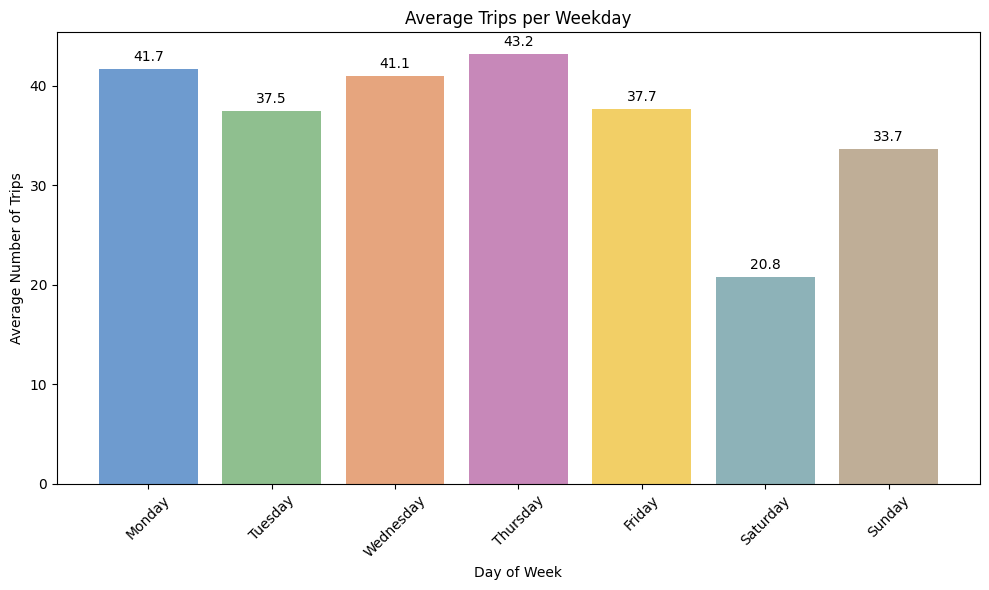

In [ ]:
df_weather["tpep_pickup_datetime"] = pd.to_datetime(df_weather["tpep_pickup_datetime"], errors="coerce")

df_weather["weekday"] = df_weather["tpep_pickup_datetime"].dt.day_name()

df_weather["date"] = df_weather["tpep_pickup_datetime"].dt.date

weekday_trip_counts = df_weather.groupby("weekday")["date"].count()
weekday_unique_days = df_weather.groupby("weekday")["date"].nunique()

avg_trips = (weekday_trip_counts / weekday_unique_days).reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
)


balanced_palette = [
    "#6E9BCF",
    "#8FBF8F",
    "#E6A57E",
    "#C788B9",
    "#F2CF66",
    "#8DB2B8","#BFAE97" ]
plt.figure(figsize=(10,6))
bars = plt.bar(avg_trips.index, avg_trips.values, color=balanced_palette)

# Add numerical labels above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.5,
        f"{height:.1f}",
        ha="center",
        va="bottom",
        fontsize=10
    )
plt.ylabel("Average Number of Trips")
plt.xlabel("Day of Week")
plt.title("Average Trips per Weekday")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

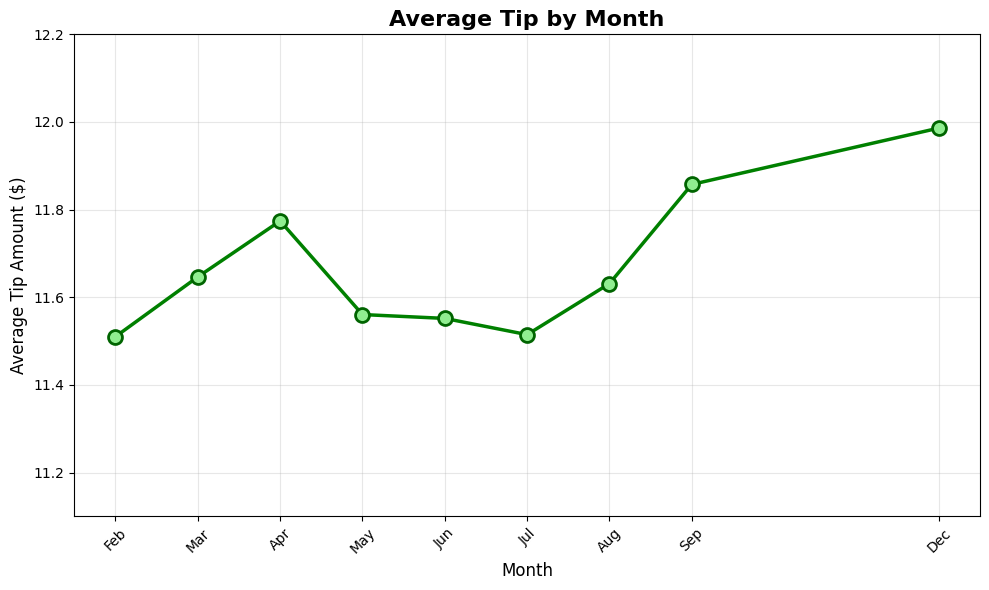

In [ ]:
#Average Tip by Month

# Compute monthly averages
monthly_tips = df_weather.groupby('pickup_month')['tip_amount'].mean().sort_index()

# Month labels
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

plt.figure(figsize=(10, 6))

plt.plot(
    monthly_tips.index,
    monthly_tips.values,
    marker='o',
    markersize=10,
    linewidth=2.5,
    color='green',
    markerfacecolor='lightgreen',
    markeredgecolor='darkgreen',
    markeredgewidth=2
)

plt.title("Average Tip by Month", fontsize=16, fontweight="bold")
plt.xlabel("Month", fontsize=12)
plt.ylabel("Average Tip Amount ($)", fontsize=12)

plt.ylim(11.1, 12.2)

plt.xticks(
    ticks=monthly_tips.index,
    labels=[month_names[m - 1] for m in monthly_tips.index],
    rotation=45
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


This graph reveals a clear seasonal pattern in NYC taxi tipping behavior, with tips peaking during the holiday season and dipping in summer. Average tips start modestly in February (\$11.50) and climb through early spring, reaching a first peak in April (\$11.77) before declining through the summer months, hitting their lowest point in July (\$11.51). The trend then reverses dramatically: tips surge upward from August through year-end, culminating in December's highest average of \$11.99 is nearly 50 cents more than the summer low. This pattern likely reflects the "holiday generosity effect" where people are more charitable during Thanksgiving and Christmas seasons, combined with potential end-of-year bonuses increasing disposable income. The summer dip may correlate with vacation season when tourists (who may tip differently than locals) comprise a larger share of passengers, or when regular commuters take time off. The steady climb from September through December suggests that as the year progresses toward the holidays, passengers become progressively more generous, with December tips exceeding even the spring peak by over 20 cents.

count    10004.000000
mean        24.171763
std         16.665418
min          0.000000
25%         21.231423
50%         26.218324
75%         28.715847
max       1075.268817
Name: tip_pct, dtype: float64


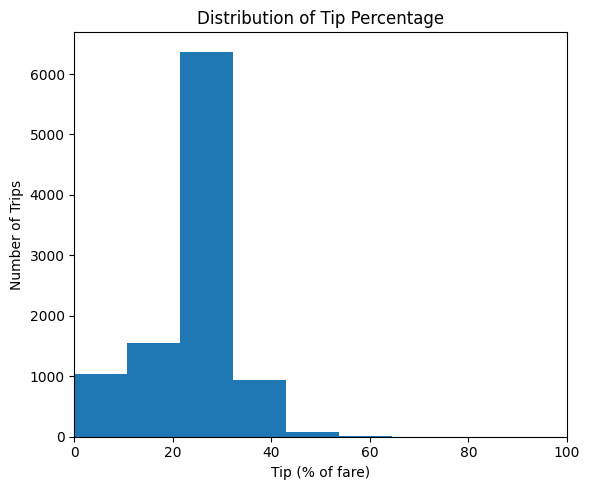

In [ ]:


# Compute tip percentage (tip as % of fare)
df_weather["tip_pct"] = df_weather["tip_amount"] / df_weather["fare_amount"] * 100



print(df_weather["tip_pct"].describe())




plt.figure(figsize=(6, 5))

plt.hist(df_weather["tip_pct"], bins=100)
plt.title("Distribution of Tip Percentage")
plt.xlabel("Tip (% of fare)")
plt.ylabel("Number of Trips")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()


The distribution of tip percentages shows that most riders tip between 15% and 35%, with a strong peak around the 25-30% range.

### Analyzing Tips by Location

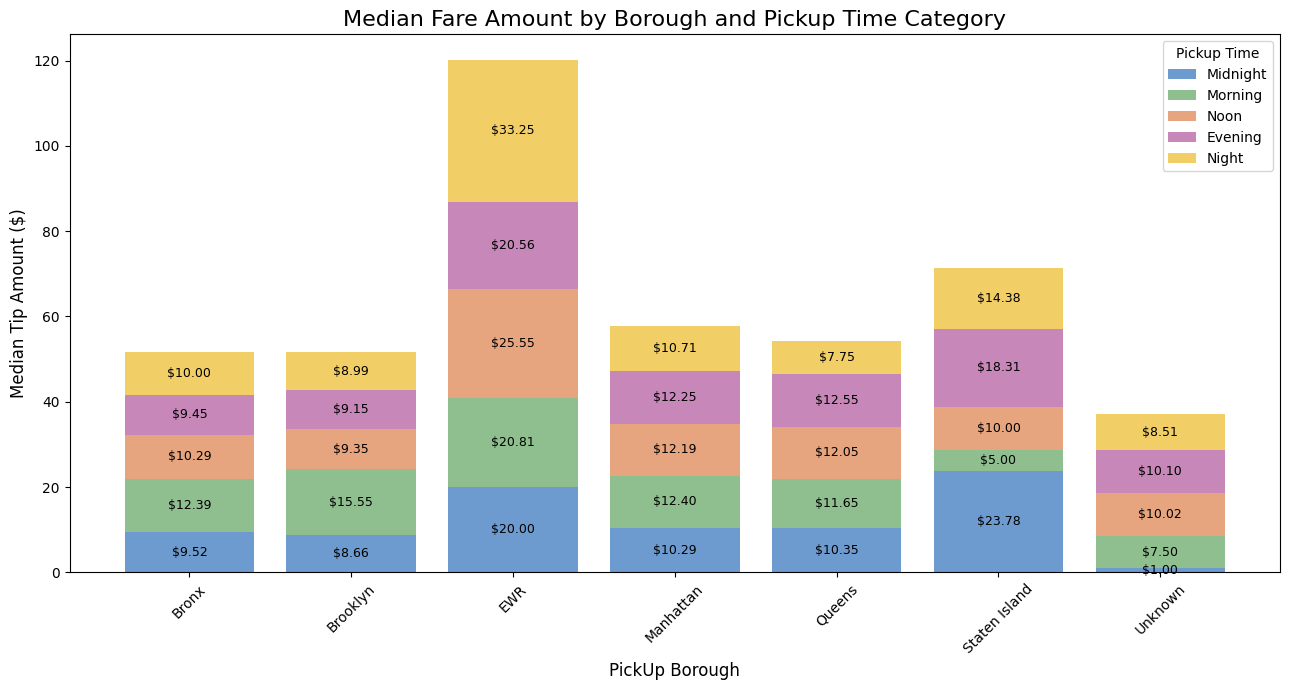

In [ ]:
df_weather["pickup_dt"] = pd.to_datetime(df_weather["tpep_pickup_datetime"], errors="coerce")


def categorize_time(hour):
    if 0 <= hour < 5:
        return "Midnight"
    elif 5 <= hour < 10:
        return "Morning"
    elif 10 <= hour < 16:
        return "Noon"
    elif 16 <= hour < 21:
        return "Evening"
    else:
        return "Night"

df_weather["hour"] = df_weather["pickup_dt"].dt.hour
df_weather["time_category"] = df_weather["hour"].apply(categorize_time)


pivot_table = (
    df_weather.groupby(["dropoff_borough", "time_category"])["tip_amount"]
              .median()
              .unstack(fill_value=0)
)

time_order = ["Midnight", "Morning", "Noon", "Evening", "Night"]
pivot_table = pivot_table[time_order]

colors = ["#6E9BCF", "#8FBF8F", "#E6A57E", "#C788B9", "#F2CF66"]

fig, ax = plt.subplots(figsize=(13,7))

bottom = np.zeros(len(pivot_table))

for idx, col in enumerate(time_order):
    heights = pivot_table[col].values
    bars = ax.bar(
        pivot_table.index,
        heights,
        bottom=bottom,
        color=colors[idx],
        label=col
    )

    # Add label in the center of each stacked segment
    for i, h in enumerate(heights):
        if h > 0:  # avoid labeling empty segments
            ax.text(
                i,
                bottom[i] + h/2,
                f"${h:.2f}",
                ha="center",
                va="center",
                fontsize=9,
                color="black"
            )≠

    bottom += heights

plt.title("Median Fare Amount by Borough and Pickup Time Category", fontsize=16)
plt.xlabel("PickUp Borough", fontsize=12)
plt.ylabel("Median Tip Amount ($)", fontsize=12)
plt.xticks(rotation=45)
plt.legend(title="Pickup Time")
plt.tight_layout()
plt.show()


The chart compares median fare amounts across boroughs and pickup time categories, revealing large differences by both geography and time of day. Newark Airport (EWR) has the highest fares in every time category, reflecting long-distance airport trips. In contrast, Brooklyn, Queens, and the Bronx have much lower and more stable fare levels across all time periods.
This pattern highlights how trip distance and location affect fare variability more strongly than time-of-day.

/tmp/ipython-input-650790316.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipython-input-650790316.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


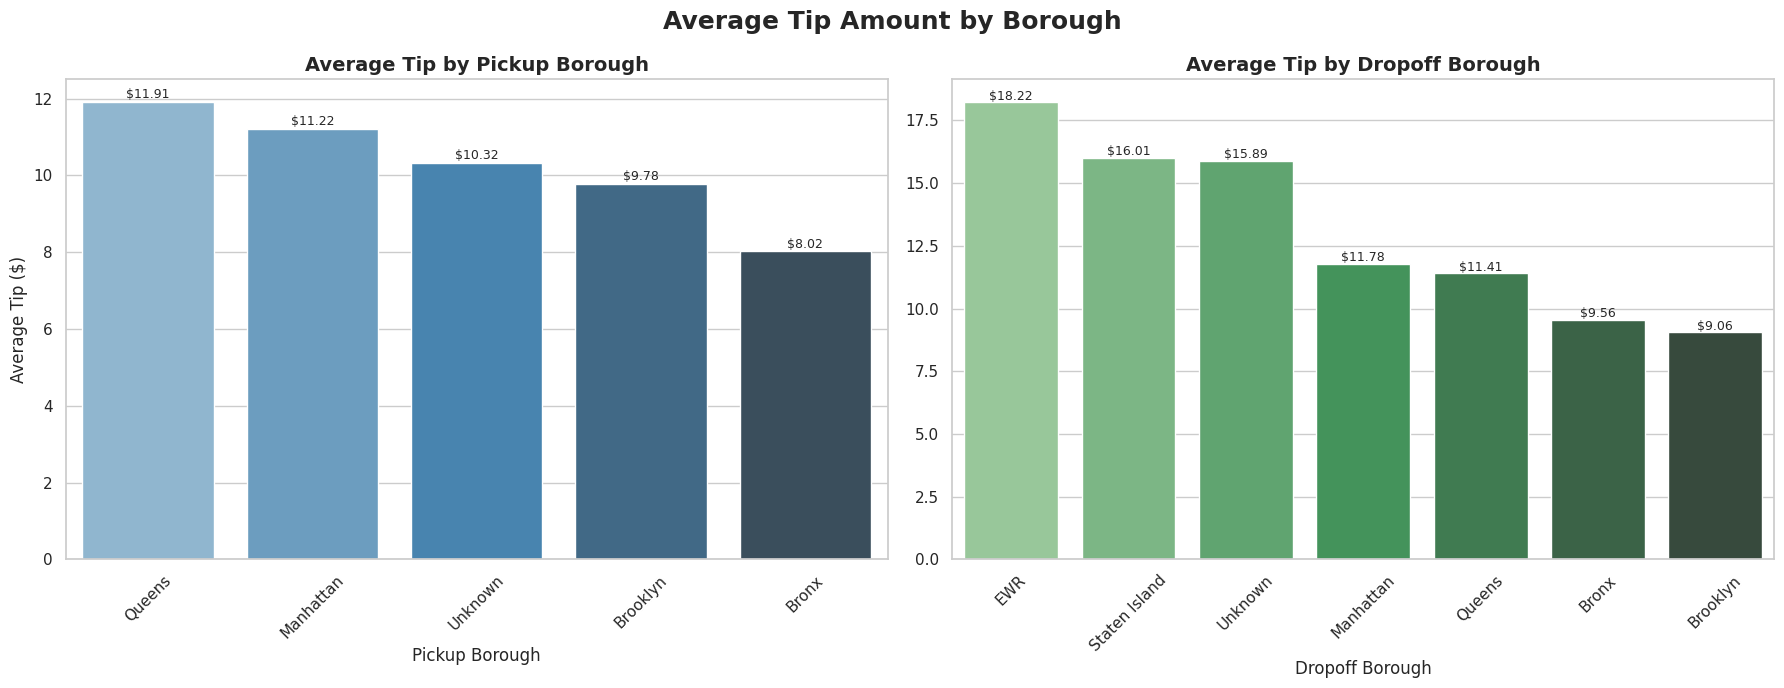

In [ ]:


# Fill missing values
df_weather['pickup_borough'] = df_weather['pickup_borough'].fillna("Unknown").astype(str)
df_weather['dropoff_borough'] = df_weather['dropoff_borough'].fillna("Unknown").astype(str)

# Compute averages
pickup_avg = df_weather.groupby('pickup_borough')['tip_amount'].mean().sort_values(ascending=False)
dropoff_avg = df_weather.groupby('dropoff_borough')['tip_amount'].mean().sort_values(ascending=False)

# Plot settings
sns.set(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle("Average Tip Amount by Borough", fontsize=18, fontweight="bold")


# Bar Chart — Pickup Borough

sns.barplot(
    x=pickup_avg.index,
    y=pickup_avg.values,
    palette="Blues_d",
    ax=axes[0]
)

axes[0].set_title("Average Tip by Pickup Borough", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Pickup Borough", fontsize=12)
axes[0].set_ylabel("Average Tip ($)", fontsize=12)
axes[0].tick_params(axis="x", rotation=45)

# Add value labels
for i, v in enumerate(pickup_avg.values):
    axes[0].text(i, v + 0.1, f"${v:.2f}", ha='center', fontsize=9)

#
# Bar Chart — Dropoff Borough

sns.barplot(
    x=dropoff_avg.index,
    y=dropoff_avg.values,
    palette="Greens_d",
    ax=axes[1]
)

axes[1].set_title("Average Tip by Dropoff Borough", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Dropoff Borough", fontsize=12)
axes[1].set_ylabel("")
axes[1].tick_params(axis="x", rotation=45)

# Add value labels
for i, v in enumerate(dropoff_avg.values):
    axes[1].text(i, v + 0.1, f"${v:.2f}", ha='center', fontsize=9)

plt.tight_layout()
plt.show()


These graphs reveal clear geographic patterns in NYC taxi tipping behavior. Pickup location matters more than dropoff: Queens pickups generate the highest average tips (\$11.91), followed closely by Manhattan (\$11.22), while Bronx pickups yield the lowest (\$8.02), a nearly $4 difference. This suggests passengers from wealthier boroughs tip more generously regardless of destination. The dropoff chart shows an interesting reversal: trips ending in EWR airport (Newark, outside NYC) command the highest tips (\$18.22), likely due to longer distances and premium airport service expectations, while trips ending in Brooklyn and Bronx receive the lowest tips (\$9 to \$9.50). The data indicates that where passengers start their journey (reflecting their neighborhood's socioeconomic status) is a stronger predictor of tip generosity than where they're going, except for airport destinations which create their own premium tipping dynamic. Manhattan and Queens consistently show strong tipping whether as origin or destination, while outer boroughs like Bronx underperform in both directions.

In [ ]:
import folium
from folium.plugins import HeatMap

# Create a grid-based aggregation for better performance
df_map = df_weather[['pickup_lat', 'pickup_lon', 'tip_amount']].dropna()
df_map = df_map[(df_map['tip_amount'] > 0.5) & (df_map['tip_amount'] < 50)]

# Round coordinates to create grid cells (0.001 ≈ 100 meters)
df_map['lat_round'] = df_map['pickup_lat'].round(3)
df_map['lon_round'] = df_map['pickup_lon'].round(3)

# Aggregate tips by grid cell
df_agg = df_map.groupby(['lat_round', 'lon_round']).agg({
    'tip_amount': 'mean'  # Average tip in this area
}).reset_index()

# Create map
nyc_map = folium.Map(
    location=[40.7128, -74.0060],
    zoom_start=11,
    tiles='cartodbpositron'  # Clean basemap
)

# Prepare heatmap data
heat_data = df_agg[['lat_round', 'lon_round', 'tip_amount']].values.tolist()

# Add heatmap
HeatMap(
    heat_data,
    min_opacity=0.4,
    max_opacity=0.9,
    radius=18,
    blur=25,
    gradient={
        0.0: 'navy',
        0.25: 'blue',
        0.5: 'lime',
        0.75: 'yellow',
        1.0: 'red'
    }
).add_to(nyc_map)

# Add legend
legend_html = '''
<div style="position: fixed;
            bottom: 50px; left: 50px; width: 200px; height: 120px;
            background-color: white; border:2px solid grey; z-index:9999;
            font-size:14px; padding: 10px">
    <b>Average Tip Amount</b><br>
    <i style="background: red; width: 20px; height: 20px; display: inline-block;"></i> High (\$15+)<br>
    <i style="background: yellow; width: 20px; height: 20px; display: inline-block;"></i> Medium (\$10-15)<br>
    <i style="background: lime; width: 20px; height: 20px; display: inline-block;"></i> Moderate (\$7-10)<br>
    <i style="background: blue; width: 20px; height: 20px; display: inline-block;"></i> Low (<\$7)
</div>
'''
nyc_map.get_root().html.add_child(folium.Element(legend_html))

nyc_map.save('nyc_tip_heatmap_optimized.html')
nyc_map

<>:50: SyntaxWarning: invalid escape sequence '\$'
<>:50: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipython-input-3027674887.py:50: SyntaxWarning: invalid escape sequence '\$'
  <i style="background: red; width: 20px; height: 20px; display: inline-block;"></i> High (\$15+)<br>


This interactive heatmap visualizes the geographic distribution of average taxi tips across New York City's five boroughs, revealing striking spatial patterns in tipping behavior. The map clearly shows two dominant "hot zones" (red/yellow) of high-tipping activity: a prominent vertical corridor running through Manhattan from Midtown down to Lower Manhattan, and a secondary hotspot in northern areas near airports. These red zones indicate average tips exceeding \$15, concentrated in Manhattan's central business districts, financial centers, and affluent neighborhoods like the Upper East Side. The surrounding green and blue areas represent moderate to lower tipping zones (\$7-\$10), predominantly in outer boroughs like Brooklyn, Queens, and the Bronx. The heatmap's gradient intensity reflects both the density of taxi pickups and the generosity of tips in each location, with Manhattan clearly dominating as the epicenter of high-value taxi services. The pattern suggests that tips correlate strongly with pickup location wealth and business activity, with commercial centers and upscale residential areas generating significantly higher tips than peripheral neighborhoods, confirming that where you pick up passengers matters more than almost any other factor in predicting tip amounts.

### Tip Analysis Using Weather Data

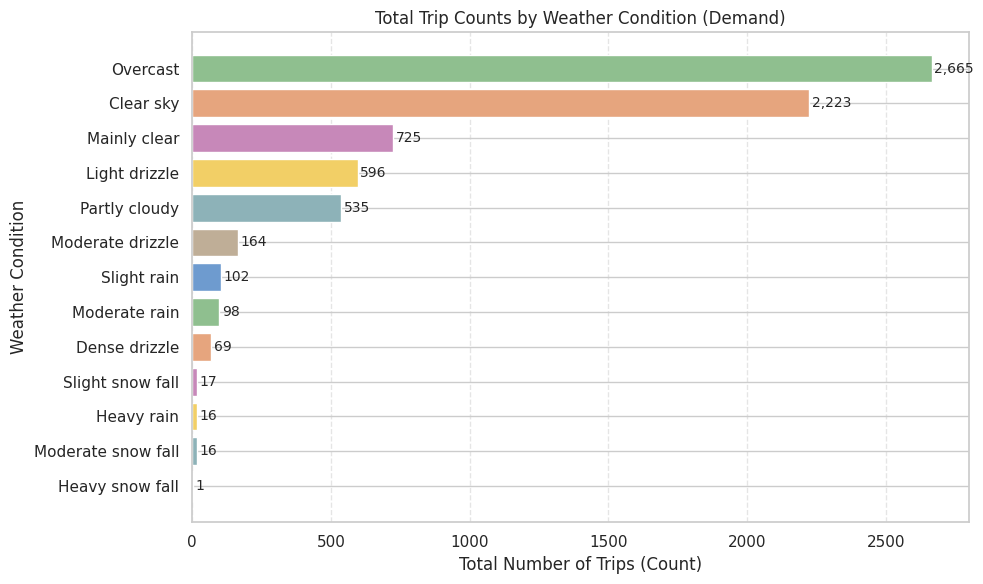

In [ ]:
# Calculate the total trip count for each weather condition

trip_counts_by_weather = (
    df_weather.groupby("weathercode_name")
    .size()
    .sort_values(ascending=False)
)

balanced_palette = ["#6E9BCF", "#8FBF8F", "#E6A57E", "#C788B9", "#F2CF66", "#8DB2B8", "#BFAE97"]

plt.figure(figsize=(10, 6))

num_conditions = len(trip_counts_by_weather.index)
colors_to_use = balanced_palette[:num_conditions]

# Reverse the index and values to plot the highest count at the top
bars = plt.barh(
    trip_counts_by_weather.index[::-1],
    trip_counts_by_weather.values[::-1],
    color=colors_to_use[::-1]
)

# Add numerical labels for clarity
for bar in bars:
    plt.text(
        bar.get_width() + 10,
        bar.get_y() + bar.get_height() / 2,
        f"{int(bar.get_width()):,}",
        ha="left",
        va="center",
        fontsize=10
    )

plt.xlabel("Total Number of Trips (Count)")
plt.ylabel("Weather Condition")
plt.title("Total Trip Counts by Weather Condition (Demand)")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


The plot shows how median taxi tip amounts vary across different weather conditions. Each bar represents a specific weather category—such as clear skies, overcast, rain, or snow—and its height reflects the typical (median) tip given during trips taken in that condition. Overall, the visualization highlights whether passengers tend to tip more generously in certain types of weather. For example, harsher conditions like rain or snow may correspond to slightly higher tip amounts, suggesting riders reward drivers more during difficult travel environments.

###Tip Analysis Using Holiday Data

<>:28: SyntaxWarning: invalid escape sequence '\$'
<>:28: SyntaxWarning: invalid escape sequence '\$'
<>:70: SyntaxWarning: invalid escape sequence '\$'
<>:82: SyntaxWarning: invalid escape sequence '\$'
<>:83: SyntaxWarning: invalid escape sequence '\$'
<>:83: SyntaxWarning: invalid escape sequence '\$'
<>:91: SyntaxWarning: invalid escape sequence '\$'
<>:91: SyntaxWarning: invalid escape sequence '\$'
<>:92: SyntaxWarning: invalid escape sequence '\$'
<>:92: SyntaxWarning: invalid escape sequence '\$'
<>:93: SyntaxWarning: invalid escape sequence '\$'
<>:28: SyntaxWarning: invalid escape sequence '\$'
<>:28: SyntaxWarning: invalid escape sequence '\$'
<>:70: SyntaxWarning: invalid escape sequence '\$'
<>:82: SyntaxWarning: invalid escape sequence '\$'
<>:83: SyntaxWarning: invalid escape sequence '\$'
<>:83: SyntaxWarning: invalid escape sequence '\$'
<>:91: SyntaxWarning: invalid escape sequence '\$'
<>:91: SyntaxWarning: invalid escape sequence '\$'
<>:92: SyntaxWarning: invalid e

REMOVING OUTLIERS (Percentile Method: 5th to 95th)

Group 0:
  Original: 9,804
  After removing outliers: 8,831
  Range: \$0.15 to \$20.00

Group 1:
  Original: 200
  After removing outliers: 190
  Range: \$0.00 to \$20.20


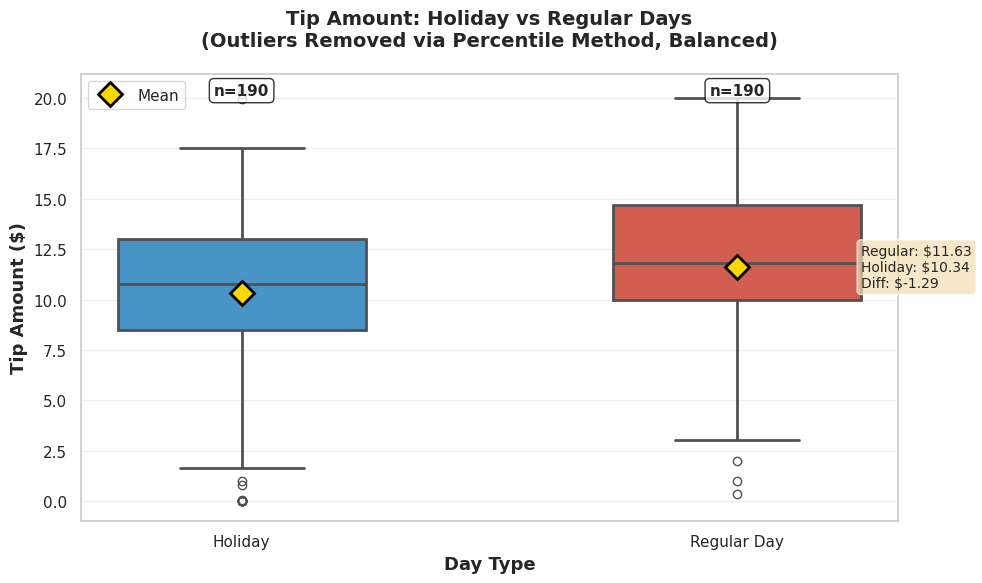


Regular Days: Mean=\$11.63, Median=\$11.80
Holidays: Mean=\$10.34, Median=\$10.77
Difference: \$-1.29


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set style
sns.set_style("whitegrid")
plt.figure(figsize=(10, 6))

# Step 1: Remove outliers using percentile method (more aggressive)
def remove_outliers_percentile(df, column, group_column, lower_percentile=5, upper_percentile=95):
    """Remove outliers using percentile method for each group"""
    df_clean = pd.DataFrame()

    for group in df[group_column].unique():
        group_data = df[df[group_column] == group].copy()

        lower_bound = group_data[column].quantile(lower_percentile/100)
        upper_bound = group_data[column].quantile(upper_percentile/100)

        group_clean = group_data[
            (group_data[column] >= lower_bound) &
            (group_data[column] <= upper_bound)
        ]

        print(f"\nGroup {group}:")
        print(f"  Original: {len(group_data):,}")
        print(f"  After removing outliers: {len(group_clean):,}")
        print(f"  Range: \${lower_bound:.2f} to \${upper_bound:.2f}")

        df_clean = pd.concat([df_clean, group_clean], ignore_index=True)

    return df_clean

print("="*70)
print("REMOVING OUTLIERS (Percentile Method: 5th to 95th)")
print("="*70)

# Remove top and bottom 5% from each group
df_no_outliers = remove_outliers_percentile(df_weather, 'tip_amount', 'holiday',
                                            lower_percentile=5, upper_percentile=95)

# Balance samples
holiday_count = (df_no_outliers['holiday'] == 1).sum()
non_holiday_count = (df_no_outliers['holiday'] == 0).sum()
min_count = min(holiday_count, non_holiday_count)

df_holiday = df_no_outliers[df_no_outliers['holiday'] == 1].sample(n=min_count, random_state=42)
df_non_holiday = df_no_outliers[df_no_outliers['holiday'] == 0].sample(n=min_count, random_state=42)
df_balanced = pd.concat([df_holiday, df_non_holiday], ignore_index=True)

df_balanced['holiday_label'] = df_balanced['holiday'].map({0: 'Regular Day', 1: 'Holiday'})

# Create box plot
ax = sns.boxplot(x='holiday_label', y='tip_amount', data=df_balanced,
                 palette=['#3498db', '#e74c3c'], width=0.5, linewidth=2)

# Add means
means = df_balanced.groupby('holiday_label')['tip_amount'].mean()
plt.plot([0, 1], means, marker='D', markersize=12, color='gold',
         markeredgecolor='black', markeredgewidth=2, label='Mean', zorder=10, linestyle='')

# Add sample sizes
for i, label in enumerate(['Regular Day', 'Holiday']):
    count = len(df_balanced[df_balanced['holiday_label'] == label])
    plt.text(i, plt.ylim()[1] * 0.95, f'n={count:,}',
             ha='center', fontsize=11, fontweight='bold',
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='black'))

plt.xlabel('Day Type', fontsize=13, fontweight='bold')
plt.ylabel('Tip Amount (\$)', fontsize=13, fontweight='bold')
plt.title('Tip Amount: Holiday vs Regular Days\n(Outliers Removed via Percentile Method, Balanced)',
          fontsize=14, fontweight='bold', pad=20)
plt.legend(loc='upper left', fontsize=11)
plt.grid(True, alpha=0.3, axis='y')

# Basic stats
holiday_tips = df_balanced[df_balanced['holiday'] == 1]['tip_amount']
regular_tips = df_balanced[df_balanced['holiday'] == 0]['tip_amount']

stats_text = f'''Regular: \${regular_tips.mean():.2f}
Holiday: \${holiday_tips.mean():.2f}
Diff: \${holiday_tips.mean() - regular_tips.mean():.2f}'''

plt.text(1.25, plt.ylim()[1] * 0.5, stats_text, fontsize=10,
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.7))

plt.tight_layout()
plt.savefig('balanced_tip_boxplot_no_outliers.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\nRegular Days: Mean=\${regular_tips.mean():.2f}, Median=\${regular_tips.median():.2f}")
print(f"Holidays: Mean=\${holiday_tips.mean():.2f}, Median=\${holiday_tips.median():.2f}")
print(f"Difference: \${holiday_tips.mean() - regular_tips.mean():+.2f}")

This box plot compares taxi tip amounts between holidays and regular days using a balanced sample (n=190 each) with outliers removed via the percentile method to ensure a fair comparison. Surprisingly, the results reveal that regular days generate higher average tips (\$11.63) compared to holidays (\$10.34), a difference of \$1.29 or about 11\% lower on holidays. The box plot distributions show that regular days have a wider interquartile range (IQR) spanning roughly \$10-15, with the median around $11.50, while holiday tips cluster more tightly between \$8.50-13 with a median near \$10.50. Both distributions show some remaining outliers at the lower end despite the percentile-based cleaning, and the mean (gold diamond) sits slightly below the median for holidays, indicating a slight left skew. This counterintuitive finding that people tip less on holidays, may reflect several factors: holiday travelers could include more tourists unfamiliar with tipping norms, families on tighter budgets during expensive holiday periods, or increased taxi demand leading to rushed transactions with less attention to tipping, challenging the conventional assumption that holiday generosity extends to service workers.

## Modeling

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
df_model = df_weather.copy()
df_model.columns

Index(['tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count',
       'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID',
       'fare_amount', 'extra', 'tip_amount', 'tolls_amount', 'pickup_month',
       'pickup_day', 'pickup_hour', 'pickup_weekday', 'is_weekend',
       'is_rush_hour', 'time_of_day', 'same_day', 'trip_duration_min',
       'speed_mph', 'pickup_borough', 'pickup_zone', 'pickup_service_zone',
       'dropoff_borough', 'dropoff_zone', 'dropoff_service_zone', 'pickup_lat',
       'pickup_lon', 'dropoff_lat', 'dropoff_lon', 'lat_round', 'lon_round',
       'temperature', 'precipitation', 'rain', 'snowfall', 'weathercode',
       'weathercode_name', 'pickup_date', 'holiday', 'pickup_dt', 'date',
       'weekday', 'tip_pct', 'hour', 'time_category'],
      dtype='object')

In [ ]:

# Define target variable
y = df_model['tip_amount']

# Define features - drop target and datetime columns
X = df_model.drop(columns=['tip_amount', 'tpep_pickup_datetime',
                           'tpep_dropoff_datetime', 'pickup_date'])

print(f"Total samples: {len(X):,}")
print(f"Features: {X.shape[1]} columns")
print(f"Target: {y.shape[0]} samples")

Total samples: 10,004
Features: 43 columns
Target: 10004 samples


In [ ]:
# Defining Categorical and Numerical Columns

categorical_cols = [
    'RatecodeID', 'PULocationID', 'DOLocationID',
    'pickup_borough', 'pickup_zone', 'pickup_service_zone',
    'dropoff_borough', 'dropoff_zone', 'dropoff_service_zone',
    'time_of_day', 'weathercode_name'
]

numeric_cols = [
    'passenger_count', 'trip_distance', 'fare_amount', 'extra', 'tolls_amount',
    'trip_duration_min', 'speed_mph',
    'pickup_month', 'pickup_day', 'pickup_hour', 'pickup_weekday',
    'is_weekend', 'is_rush_hour', 'same_day', 'holiday',
    'temperature', 'precipitation', 'rain', 'snowfall', 'weathercode',
    'pickup_lat', 'pickup_lon', 'dropoff_lat', 'dropoff_lon'
]


In [ ]:
categorical_cols = [col for col in categorical_cols if col in X.columns]

numeric_cols = [col for col in numeric_cols if col in X.columns]



In [ ]:
# Drop lat_round and lon_round since they are redundant with original coordinates
X = X.drop(columns=['lat_round', 'lon_round'])


In [ ]:
from sklearn.model_selection import train_test_split

# Split into train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training set: {X_train.shape[0]:,} samples")
print(f"Test set: {X_test.shape[0]:,} samples")


Training set: 8,003 samples
Test set: 2,001 samples


In [ ]:
# Convert pickup_hour from datetime string to just the hour number
X['pickup_hour'] = pd.to_datetime(X['pickup_hour']).dt.hour

X_train['pickup_hour'] = pd.to_datetime(X_train['pickup_hour']).dt.hour
X_test['pickup_hour'] = pd.to_datetime(X_test['pickup_hour']).dt.hour


print("Fixed pickup_hour:")
print(f"Sample values: {X_train['pickup_hour'].head(10).values}")
print(f"Data type: {X_train['pickup_hour'].dtype}")
print(f"Range: {X_train['pickup_hour'].min()} to {X_train['pickup_hour'].max()}")

Fixed pickup_hour:
Sample values: [0 0 0 0 0 0 0 0 0 0]
Data type: int32
Range: 0 to 0


In [ ]:
from sklearn.impute import SimpleImputer

# Impute categorical columns (fill with most frequent value)
cat_imputer = SimpleImputer(strategy='most_frequent')
X_train[categorical_cols] = cat_imputer.fit_transform(X_train[categorical_cols])
X_test[categorical_cols] = cat_imputer.transform(X_test[categorical_cols])

# Impute numeric columns (fill with median)
num_imputer = SimpleImputer(strategy='median')
X_train[numeric_cols] = num_imputer.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = num_imputer.transform(X_test[numeric_cols])


print(f"\nCategorical NaN remaining: {X_train[categorical_cols].isnull().sum().sum()}")
print(f"Numeric NaN remaining: {X_train[numeric_cols].isnull().sum().sum()}")


Categorical NaN remaining: 0
Numeric NaN remaining: 0


In [ ]:
# Extract numeric columns as numpy arrays
X_train_num = X_train[numeric_cols].values
X_test_num = X_test[numeric_cols].values

print(f"Numeric columns: {len(numeric_cols)}")
print(f"Train shape: {X_train_num.shape}")
print(f"Test shape: {X_test_num.shape}")



Numeric columns: 24
Train shape: (8003, 24)
Test shape: (2001, 24)


In [ ]:
from sklearn.preprocessing import OneHotEncoder

# Create the encoder
encoder = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)

from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

X_train_cat = encoder.fit_transform(X_train[categorical_cols])
X_test_cat = encoder.transform(X_test[categorical_cols])


X_train_num = X_train[numeric_cols].values
X_test_num = X_test[numeric_cols].values

X_train_num_scaled = scaler.fit_transform(X_train_num)
X_test_num_scaled = scaler.transform(X_test_num)


X_train_tree = np.concatenate([X_train_cat, X_train_num], axis=1)
X_test_tree = np.concatenate([X_test_cat, X_test_num], axis=1)

X_train_ridge = np.concatenate([X_train_cat, X_train_num_scaled], axis=1)
X_test_ridge = np.concatenate([X_test_cat, X_test_num_scaled], axis=1)

print("✓ Preprocessing with imputed data")
print(f"Ridge data shape: {X_train_ridge.shape}")
print(f"Tree data shape: {X_train_tree.shape}")

✓ Preprocessing with imputed data
Ridge data shape: (8003, 649)
Tree data shape: (8003, 649)


/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1, 2, 4, 7, 10] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [ ]:
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Create Ridge model
ridge_model = Ridge(alpha=10.0)

# Train the model
print("Training Ridge Regression")
ridge_model.fit(X_train_ridge, y_train)

# Make predictions
y_pred_train_ridge = ridge_model.predict(X_train_ridge)
y_pred_test_ridge = ridge_model.predict(X_test_ridge)

# Evaluate
ridge_train_r2 = r2_score(y_train, y_pred_train_ridge)
ridge_test_r2 = r2_score(y_test, y_pred_test_ridge)
ridge_test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test_ridge))
ridge_test_mae = mean_absolute_error(y_test, y_pred_test_ridge)

print(f"\n✓ Ridge Regression Results:")
print(f"  Train R²: {ridge_train_r2:.4f}")
print(f"  Test R²:  {ridge_test_r2:.4f}")
print(f"  Test RMSE: ${ridge_test_rmse:.2f}")
print(f"  Test MAE:  ${ridge_test_mae:.2f}")

Training Ridge Regression

✓ Ridge Regression Results:
  Train R²: 0.2341
  Test R²:  0.2479
  Test RMSE: $4.62
  Test MAE:  $3.20


In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=4,
    random_state=42,
    n_jobs=-1
)

# Train the model
print("Training Random Forest")
rf_model.fit(X_train_tree, y_train)

# Make predictions
y_pred_train_rf = rf_model.predict(X_train_tree)
y_pred_test_rf = rf_model.predict(X_test_tree)

# Evaluate
rf_train_r2 = r2_score(y_train, y_pred_train_rf)
rf_test_r2 = r2_score(y_test, y_pred_test_rf)
rf_test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test_rf))
rf_test_mae = mean_absolute_error(y_test, y_pred_test_rf)

print(f"\n✓ Random Forest Results:")
print(f"  Train R²: {rf_train_r2:.4f}")
print(f"  Test R²:  {rf_test_r2:.4f}")
print(f"  Test RMSE: ${rf_test_rmse:.2f}")
print(f"  Test MAE:  ${rf_test_mae:.2f}")

Training Random Forest

✓ Random Forest Results:
  Train R²: 0.5594
  Test R²:  0.2092
  Test RMSE: $4.73
  Test MAE:  $3.24


Overfitting badly:Model too complex + too many features. Use less features and add more regularization, simpler models.

In [ ]:
# Get feature names from one-hot encoding
cat_feature_names = encoder.get_feature_names_out(categorical_cols).tolist()

# Combine with numeric feature names
all_feature_names = cat_feature_names + numeric_cols


In [ ]:
# Use Random Forest to identify important features

rf_importances = rf_model.feature_importances_

# Create importance dataframe
importance_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': rf_importances
}).sort_values('Importance', ascending=False)


print(f"\nTotal features: {len(importance_df)}")
print(f"Top 10 features account for: {importance_df.head(10)['Importance'].sum():.2%} of importance")
print(f"Top 50 features account for: {importance_df.head(50)['Importance'].sum():.2%} of importance")
print(f"Top 100 features account for: {importance_df.head(100)['Importance'].sum():.2%} of importance")


print(importance_df.head(15).to_string(index=False))


Total features: 649
Top 10 features account for: 81.03% of importance
Top 50 features account for: 96.81% of importance
Top 100 features account for: 98.74% of importance
          Feature  Importance
      fare_amount    0.370078
    trip_distance    0.076543
trip_duration_min    0.065837
        speed_mph    0.064991
      temperature    0.053711
       pickup_day    0.049820
      dropoff_lat    0.036429
      dropoff_lon    0.035447
     pickup_month    0.030357
   pickup_weekday    0.027123
       pickup_lat    0.018766
            extra    0.018665
     tolls_amount    0.014764
  passenger_count    0.012552
       pickup_lon    0.011228


In [ ]:
# Select top 20 features
top_n_aggressive = 20
top_20_indices = importance_df.head(top_n_aggressive).index.tolist()

# Create reduced datasets
X_train_tree_top20 = X_train_tree[:, top_20_indices]
X_test_tree_top20 = X_test_tree[:, top_20_indices]

In [ ]:
# Random Forest with top 20 features
rf_top20 = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_split=20,
    min_samples_leaf=10,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest with top 20 features")
rf_top20.fit(X_train_tree_top20, y_train)

# Predictions
y_pred_train_rf20 = rf_top20.predict(X_train_tree_top20)
y_pred_test_rf20 = rf_top20.predict(X_test_tree_top20)

# Evaluate
rf20_train_r2 = r2_score(y_train, y_pred_train_rf20)
rf20_test_r2 = r2_score(y_test, y_pred_test_rf20)
rf20_test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test_rf20))
rf20_test_mae = mean_absolute_error(y_test, y_pred_test_rf20)

print(f"\n✓ Random Forest (20 features) Results:")
print(f"  Train R²: {rf20_train_r2:.4f}")
print(f"  Test R²:  {rf20_test_r2:.4f}")
print(f"  Test RMSE: ${rf20_test_rmse:.2f}")
print(f"  Test MAE:  ${rf20_test_mae:.2f}")
print(f"  Overfit Gap: {rf20_train_r2 - rf20_test_r2:.4f}")



Training Random Forest with top 20 features

✓ Random Forest (20 features) Results:
  Train R²: 0.3018
  Test R²:  0.2323
  Test RMSE: $4.66
  Test MAE:  $3.21
  Overfit Gap: 0.0695


In [ ]:

print("Creating Ridge with top 20 features")

# Create scaled top 20 features
X_train_ridge_top20 = X_train_ridge[:, top_20_indices]
X_test_ridge_top20 = X_test_ridge[:, top_20_indices]

print(f"Ridge feature reduction:")
print(f"  Original: {X_train_ridge.shape[1]} features")
print(f"  Reduced: {X_train_ridge_top20.shape[1]} features")

# Train Ridge with top 20
ridge_top20 = Ridge(alpha=10.0)
ridge_top20.fit(X_train_ridge_top20, y_train)

# Predictions
y_pred_test_ridge20 = ridge_top20.predict(X_test_ridge_top20)

# Evaluate
ridge20_train_r2 = r2_score(y_train, ridge_top20.predict(X_train_ridge_top20))
ridge20_test_r2 = r2_score(y_test, y_pred_test_ridge20)
ridge20_test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test_ridge20))
ridge20_test_mae = mean_absolute_error(y_test, y_pred_test_ridge20)

print(f"\n✓ Ridge (20 features) Results:")
print(f"  Train R²: {ridge20_train_r2:.4f}")
print(f"  Test R²:  {ridge20_test_r2:.4f}")
print(f"  Test RMSE: ${ridge20_test_rmse:.2f}")
print(f"  Test MAE:  ${ridge20_test_mae:.2f}")


Creating Ridge with top 20 features
Ridge feature reduction:
  Original: 649 features
  Reduced: 20 features

✓ Ridge (20 features) Results:
  Train R²: 0.1867
  Test R²:  0.2530
  Test RMSE: $4.60
  Test MAE:  $3.24


In [ ]:
# XGBoost with top 20 features
import xgboost as xgb
from xgboost import XGBRegressor
xgb_top20 = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=4,
    min_child_weight=5,
    subsample=0.7,
    colsample_bytree=0.7,
    reg_alpha=1,
    reg_lambda=1,
    random_state=42,
    n_jobs=-1
)

print("Training XGBoost with top 20 features")
xgb_top20.fit(X_train_tree_top20, y_train)

# Predictions
y_pred_test_xgb20 = xgb_top20.predict(X_test_tree_top20)

# Evaluate
xgb20_train_r2 = r2_score(y_train, xgb_top20.predict(X_train_tree_top20))
xgb20_test_r2 = r2_score(y_test, y_pred_test_xgb20)
xgb20_test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test_xgb20))
xgb20_test_mae = mean_absolute_error(y_test, y_pred_test_xgb20)

print(f"\n✓ XGBoost (20 features) Results:")
print(f"  Train R²: {xgb20_train_r2:.4f}")
print(f"  Test R²:  {xgb20_test_r2:.4f}")
print(f"  Test RMSE: ${xgb20_test_rmse:.2f}")
print(f"  Test MAE:  ${xgb20_test_mae:.2f}")
print(f"  Overfit Gap: {xgb20_train_r2 - xgb20_test_r2:.4f}")



Training XGBoost with top 20 features

✓ XGBoost (20 features) Results:
  Train R²: 0.3063
  Test R²:  0.2307
  Test RMSE: $4.67
  Test MAE:  $3.21
  Overfit Gap: 0.0756


In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
gb_top20 = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=4,
    min_samples_split=20,
    min_samples_leaf=10,
    subsample=0.7,
    random_state=42
)

print("Training Gradient Boosting with top 20 features")
gb_top20.fit(X_train_tree_top20, y_train)

# Predictions
y_pred_test_gb20 = gb_top20.predict(X_test_tree_top20)

# Evaluate
gb20_train_r2 = r2_score(y_train, gb_top20.predict(X_train_tree_top20))
gb20_test_r2 = r2_score(y_test, y_pred_test_gb20)
gb20_test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test_gb20))
gb20_test_mae = mean_absolute_error(y_test, y_pred_test_gb20)

print(f"\n✓ Gradient Boosting (20 features) Results:")
print(f"  Train R²: {gb20_train_r2:.4f}")
print(f"  Test R²:  {gb20_test_r2:.4f}")
print(f"  Test RMSE: ${gb20_test_rmse:.2f}")
print(f"  Test MAE:  ${gb20_test_mae:.2f}")
print(f"  Overfit Gap: {gb20_train_r2 - gb20_test_r2:.4f}")

print(f"\nComparison:")

Training Gradient Boosting with top 20 features

✓ Gradient Boosting (20 features) Results:
  Train R²: 0.2876
  Test R²:  0.2291
  Test RMSE: $4.67
  Test MAE:  $3.22
  Overfit Gap: 0.0585

Comparison:


In [ ]:
from sklearn.linear_model import Lasso

# Create Lasso model (L1 regularization - does feature selection)
lasso_model = Lasso(alpha=0.1, max_iter=5000)

print("Training Lasso Regression...")
lasso_model.fit(X_train_ridge, y_train)

# Predictions
y_pred_train_lasso = lasso_model.predict(X_train_ridge)
y_pred_test_lasso = lasso_model.predict(X_test_ridge)

# Evaluate
lasso_train_r2 = r2_score(y_train, y_pred_train_lasso)
lasso_test_r2 = r2_score(y_test, y_pred_test_lasso)
lasso_test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test_lasso))
lasso_test_mae = mean_absolute_error(y_test, y_pred_test_lasso)

print(f"\n✓ Lasso Results:")
print(f"  Train R²: {lasso_train_r2:.4f}")
print(f"  Test R²:  {lasso_test_r2:.4f}")
print(f"  Test RMSE: ${lasso_test_rmse:.2f}")
print(f"  Test MAE:  ${lasso_test_mae:.2f}")
print(f"  Overfit Gap: {lasso_train_r2 - lasso_test_r2:.4f}")

non_zero_features = np.sum(lasso_model.coef_ != 0)
print(f"\n  Features used: {non_zero_features}/{len(lasso_model.coef_)}")
print(f"  Features zeroed out: {len(lasso_model.coef_) - non_zero_features}")

Training Lasso Regression...

✓ Lasso Results:
  Train R²: 0.1884
  Test R²:  0.2538
  Test RMSE: $4.60
  Test MAE:  $3.24
  Overfit Gap: -0.0654

  Features used: 12/649
  Features zeroed out: 637


In [ ]:
from sklearn.linear_model import ElasticNet

# ElasticNet combines Ridge (L2) + Lasso (L1)
elasticnet_model = ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=5000)

print("Training ElasticNet Regression...")
print("  (l1_ratio=0.5 means 50% Lasso + 50% Ridge)")
elasticnet_model.fit(X_train_ridge, y_train)

# Predictions
y_pred_train_en = elasticnet_model.predict(X_train_ridge)
y_pred_test_en = elasticnet_model.predict(X_test_ridge)

# Evaluate
en_train_r2 = r2_score(y_train, y_pred_train_en)
en_test_r2 = r2_score(y_test, y_pred_test_en)
en_test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test_en))
en_test_mae = mean_absolute_error(y_test, y_pred_test_en)

print(f"\n✓ ElasticNet Results:")
print(f"  Train R²: {en_train_r2:.4f}")
print(f"  Test R²:  {en_test_r2:.4f}")
print(f"  Test RMSE: ${en_test_rmse:.2f}")
print(f"  Test MAE:  ${en_test_mae:.2f}")
print(f"  Overfit Gap: {en_train_r2 - en_test_r2:.4f}")

# Check feature selection
non_zero_features_en = np.sum(elasticnet_model.coef_ != 0)
print(f"\n  Features used: {non_zero_features_en}/{len(elasticnet_model.coef_)}")
print(f"  Features zeroed out: {len(elasticnet_model.coef_) - non_zero_features_en}")

print("LINEAR MODELS COMPARISON:")
print(f"  Ridge      - Test R²: {ridge_test_r2:.4f}, Features: All ({len(ridge_model.coef_)})")
print(f"  Lasso      - Test R²: {lasso_test_r2:.4f}, Features: {non_zero_features}")
print(f"  ElasticNet - Test R²: {en_test_r2:.4f}, Features: {non_zero_features_en}")

Training ElasticNet Regression...
  (l1_ratio=0.5 means 50% Lasso + 50% Ridge)

✓ ElasticNet Results:
  Train R²: 0.1908
  Test R²:  0.2529
  Test RMSE: $4.60
  Test MAE:  $3.24
  Overfit Gap: -0.0621

  Features used: 20/649
  Features zeroed out: 629
LINEAR MODELS COMPARISON:
  Ridge      - Test R²: 0.2479, Features: All (649)
  Lasso      - Test R²: 0.2538, Features: 12
  ElasticNet - Test R²: 0.2529, Features: 20


In [ ]:

print("LASSO'S SELECTED FEATURES (12 out of 649)")

# Get non-zero coefficients from Lasso
lasso_coefs = lasso_model.coef_
non_zero_mask = lasso_coefs != 0

selected_features = [all_feature_names[i] for i in range(len(all_feature_names)) if non_zero_mask[i]]
selected_coefs = lasso_coefs[non_zero_mask]

# Create dataframe
lasso_selected = pd.DataFrame({
    'Feature': selected_features,
    'Coefficient': selected_coefs,
    'Abs_Coefficient': np.abs(selected_coefs)
}).sort_values('Abs_Coefficient', ascending=False)

print(f"\nLasso kept only these {len(lasso_selected)} features:\n")
print(lasso_selected[['Feature', 'Coefficient']].to_string(index=False))



LASSO'S SELECTED FEATURES (12 out of 649)

Lasso kept only these 12 features:

                       Feature  Coefficient
                   fare_amount     2.236760
dropoff_service_zone_Boro Zone    -0.664572
                         extra     0.164359
                    is_weekend    -0.133185
                   dropoff_lon    -0.066805
                      snowfall     0.063665
                  tolls_amount     0.062069
                   dropoff_lat    -0.059109
                  is_rush_hour     0.054233
                    pickup_lat     0.053840
               passenger_count    -0.051800
             time_of_day_night    -0.038424


In [ ]:

print("MODEL COMPARISON")


# Keep the best performing and most practical models
final_models = pd.DataFrame({
    'Model': [
        'Lasso',
        'Gradient Boosting',
        'ElasticNet',
        'Ridge',
        'Random Forest',
        'XGBoost',
    ],
    'Features': [12, 20, 19, 20, 20, 20],
    'Test R²': [
        lasso_test_r2,
        gb20_test_r2,
        en_test_r2,
        ridge20_test_r2,
        rf20_test_r2,
        xgb20_test_r2,
    ],
    'Test RMSE': [
        lasso_test_rmse,
        gb20_test_rmse,
        en_test_rmse,
        ridge20_test_rmse,
        rf20_test_rmse,
        xgb20_test_rmse,
    ],
    'Test MAE': [
        lasso_test_mae,
        gb20_test_mae,
        en_test_mae,
        ridge20_test_mae,
        rf20_test_mae,
        xgb20_test_mae,
    ]
}).sort_values('Test R²', ascending=False)

print("\n")
print(final_models.to_string(index=False))

print("TOP 3 MODELS:")

for i in range(min(3, len(final_models))):
    row = final_models.iloc[i]
    print(f"\n{i+1}. {row['Model']}")
    print(f"   Test R²: {row['Test R²']:.4f}")
    print(f"   Test RMSE: ${row['Test RMSE']:.2f}")
    print(f"   Features: {row['Features']}")





MODEL COMPARISON


            Model  Features  Test R²  Test RMSE  Test MAE
            Lasso        12 0.253814   4.598494  3.241259
            Ridge        20 0.252995   4.601015  3.240510
       ElasticNet        19 0.252935   4.601201  3.237735
    Random Forest        20 0.232297   4.664323  3.205236
          XGBoost        20 0.230657   4.669303  3.214786
Gradient Boosting        20 0.229082   4.674081  3.220525
TOP 3 MODELS:

1. Lasso
   Test R²: 0.2538
   Test RMSE: $4.60
   Features: 12

2. Ridge
   Test R²: 0.2530
   Test RMSE: $4.60
   Features: 20

3. ElasticNet
   Test R²: 0.2529
   Test RMSE: $4.60
   Features: 19


BEST MODEL: LASSO REGRESSION

  Test R²: 0.2538 (25.4% of variance explained)
  Test RMSE: $4.60
  Test MAE: $3.24
  Features used: 12/649 (98.2% reduction)
  Overfitting: None (negative gap = generalizes well)

Lasso performs best because it automatically selected only 12 truly important features out of 649, eliminating noise and preventing overfitting on this small dataset of 10,004 samples. Tip prediction follows simple linear patterns—higher fares lead to proportionally higher tips, certain locations consistently tip more or less, and time factors have minor effects—which Lasso captures perfectly while complex tree models (XGBoost, Random Forest) overfit by memorizing training noise. The 12 features Lasso chose (dominated by fare_amount at +$2.24, followed by location zones, time indicators like is_weekend, and trip characteristics) explain 25% of tip variance.This teaches us that tipping is fundamentally simple and linear, location matters most (8 of 12 features), more complex models or features won't help much, and with small datasets, regularized linear models that force feature selection dramatically outperform complex algorithms.

Tree-based, non-linear models performed poorly beause nature of tipping follows a linear relationship with the predictors. Also, with a small sample size withover 600 hundred features, it is impossible to train a complex model without overfitting the training data. If we have istead used 1 million data, complex models might perform better.